# MOSAIC-GNN — pan-cancer multi-omics graph neural network

**M**ulti-**O**mic **S**tructure-**A**daptive **I**nterpretable **C**ross-cancer GNN
on TCGA (BLCA, LIHC, THCA and lung adenocarcinoma).

Each patient is encoded as a *graph of genes* (mutation / CNA / expression /
methylation channels on nodes, PPI + pathway + co-alteration edges), pooled into
functional modules, and the resulting patient vector becomes a node in a
*learned patient-similarity graph*. A cohort-adversarial split of the latent
(`z_shared` vs `z_specific`) is what makes the representation transfer to a
held-out cancer type rather than memorising the cohort.

Heads: stage/grade/subtype classification, Cox risk, and a discrete-time hazard
curve — trained jointly.

### How to use this notebook
1. Run **Setup** and **Configuration**.
2. **Explore** the cohorts.
3. **Single fold** trains one model quickly and produces the figures.
4. **Full experiments** (CV, baselines, ablations, leave-one-cancer-out) are
   guarded by `RUN_FULL` — flip it on when you have GPU time.
5. **Interpretation** produces the gene / module tables and the paper figures.

## 1. Setup

In [1]:
# The whole `mosaic` package, zipped and base64-encoded, so this notebook
# is self-contained: no companion dataset, no upload, nothing to attach.
MOSAIC_PKG_B64 = (
    "..."
)

In [2]:
import os, sys, subprocess, glob, warnings, json, base64, io, shutil, zipfile
warnings.filterwarnings("ignore")

# Set to True only when you are editing mosaic/ next to the notebook and want
# your local copy to win. Default False on purpose: /kaggle/working persists
# between sessions, so an older extraction left there would silently shadow the
# version embedded above and you would debug bugs that are already fixed.
USE_LOCAL_PACKAGE = False

DEST = "/kaggle/working/mosaic-pkg" if os.path.isdir("/kaggle/working") \
       else os.path.abspath("./mosaic-pkg")

PKG_ROOT = None
if USE_LOCAL_PACKAGE:
    PKG_ROOT = next((os.path.abspath(p) for p in (".", "..")
                     if os.path.isfile(os.path.join(p, "mosaic", "config.py"))),
                    None)

if PKG_ROOT is None:
    # Always wipe and re-extract: never trust what a previous run left behind.
    shutil.rmtree(DEST, ignore_errors=True)
    os.makedirs(DEST, exist_ok=True)
    zipfile.ZipFile(io.BytesIO(base64.b64decode(MOSAIC_PKG_B64))).extractall(DEST)
    PKG_ROOT = DEST
    print("extracted embedded package ->", DEST)

# Drop anything already imported under the `mosaic` name, or a stale module
# object would survive the path change.
for name in [m for m in list(sys.modules) if m == "mosaic" or m.startswith("mosaic.")]:
    del sys.modules[name]
while PKG_ROOT in sys.path:
    sys.path.remove(PKG_ROOT)
sys.path.insert(0, PKG_ROOT)

# Fail loudly now rather than with a confusing traceback 40 minutes in.
assert os.path.isfile(os.path.join(PKG_ROOT, "mosaic", "config.py")), \
    "extraction produced no mosaic/config.py"
_layers = open(os.path.join(PKG_ROOT, "mosaic", "models", "layers.py")).read()
assert "autocast(device_type=z.device.type, enabled=False)" in _layers, \
    "loaded layers.py predates the mixed-precision dtype fix -- stale package"
print("package root:", PKG_ROOT)

for pkg in ("torch", "sklearn", "scipy", "pandas", "matplotlib"):
    try:
        __import__(pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        {"sklearn": "scikit-learn"}.get(pkg, pkg)], check=True)

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
print("torch", torch.__version__, "| cuda", torch.cuda.is_available())

extracted embedded package -> /home/user/multi-omic-structure-adaptive-interpretable-cross-cancer/mosaic-pkg
package root: /home/user/multi-omic-structure-adaptive-interpretable-cross-cancer/mosaic-pkg


torch 2.15.0+cu132 | cuda False


## 2. The manuscript results

**Read this section first, and quote only from it.**

Every number in the project report comes from two runs that were executed
once, at full settings, and then exported: the 32-class `cohort` run and the
`stage_binary` run. Those exports travel inside the zip embedded in Section 1,
so the cells below reproduce the report's tables wherever this notebook is
opened, without refitting anything and without a network call.

This matters because of a trap that caught an earlier version of this
notebook. Section 4 onwards *retrains* the model at a deliberately reduced
configuration so that the notebook finishes in about an hour. A reduced run
produces different numbers — the same architecture on fewer genes for fewer
epochs is simply a different experiment — so the figures it prints are **not**
the report's figures and must never be quoted as though they were. The two
are kept apart here: Section 2 is the report, Sections 4 to 8 are a
demonstration you can run yourself. The last cell of this section checks the
agreement automatically, so you do not have to take that on trust.

In [3]:
# Locate the manuscript artefacts: the extracted zip first, then the
# repository, so this works both on Kaggle and next to a checkout.
import os, sys, json

CANDIDATES = [PKG_ROOT, os.path.abspath("."), os.path.abspath("..")]
ART_ROOT = next((c for c in CANDIDATES
                 if os.path.isfile(os.path.join(
                     c, "runs_pan_cohort", "table2_single_fold.csv"))), None)
assert ART_ROOT, ("the manuscript exports are missing; rebuild the notebook "
                  "with scripts/build_notebook.py from a full checkout")

RUNS_COHORT = os.path.join(ART_ROOT, "runs_pan_cohort")
RUNS_STAGE  = os.path.join(ART_ROOT, "runs_pan_stage")
PAYLOAD     = os.path.join(ART_ROOT, "deliverables",
                           "manuscript_payload.json")

sys.path.insert(0, os.path.join(ART_ROOT, "scripts"))
if os.path.isdir(os.path.join(ART_ROOT, "scripts")):
    sys.path.insert(0, os.path.join(ART_ROOT, "scripts"))
import report_analysis as RA          # the module the report itself uses

A = RA.analyse(RUNS_COHORT)           # derived analyses, cohort run
S = RA.analyse(RUNS_STAGE)            # derived analyses, stage_binary run

print("artefact root :", ART_ROOT)
print("cohort run    :", RUNS_COHORT)
print("stage run     :", RUNS_STAGE)
print("phases present in the cohort run:",
      ", ".join(k for k, v in A.items() if v and k not in ("runs", "panel")))
print("phases present in the stage run :",
      ", ".join(k for k, v in S.items() if v and k not in ("runs", "panel")))

artefact root : /home/user/multi-omic-structure-adaptive-interpretable-cross-cancer/mosaic-pkg
cohort run    : /home/user/multi-omic-structure-adaptive-interpretable-cross-cancer/mosaic-pkg/runs_pan_cohort
stage run     : /home/user/multi-omic-structure-adaptive-interpretable-cross-cancer/mosaic-pkg/runs_pan_stage
phases present in the cohort run: descriptives, per_class, class_names, consistency, gap, ranks, paired, ablation, permutation, samplesize, loco, interpretation, per_cohort, per_cohort_degeneracy, cost
phases present in the stage run : descriptives, per_class, class_names, consistency, gap, ranks, paired, interpretation, per_cohort, per_cohort_degeneracy, cost


### 2.1 The assembled dataset

Descriptive statistics of the data both runs were fitted on. Everything here
is computed from the exported cohort table; the entropy is in nats and its
maximum `ln K` is what a perfectly balanced set of `K` cohorts would give.

In [4]:
import pandas as pd
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 200)

d = A["descriptives"]
rows = [
    ("studies (K)",                  d["n_cohorts"]),
    ("patients",                     int(d["patients_total"])),
    ("observed deaths",              int(d["events_total"])),
    ("pooled event rate",            round(d["pooled_event_rate"], 4)),
    ("smallest cohort",              f"{int(d['patients_min'])} ({d['patients_min_cohort']})"),
    ("largest cohort",               f"{int(d['patients_max'])} ({d['patients_max_cohort']})"),
    ("median cohort size",           d["patients_median"]),
    ("imbalance ratio",              round(d["imbalance_ratio"], 2)),
    ("Shannon entropy H (nats)",     round(d["entropy_nats"], 4)),
    ("maximum entropy ln K",         round(d["entropy_max"], 4)),
    ("normalised entropy H / ln K",  round(d["entropy_ratio"], 4)),
    ("Gini impurity",                round(d["gini"], 4)),
    ("lowest event rate",            f"{d['event_rate_min']} ({d['event_rate_min_cohort']})"),
    ("highest event rate",           f"{d['event_rate_max']} ({d['event_rate_max_cohort']})"),
    ("cohorts under 20 events",      d["n_events_below_20"]),
    ("cohorts under 60 events",      d["n_events_below_60"]),
]
print(pd.DataFrame(rows, columns=["quantity", "value"]).to_string(index=False))

                   quantity        value
                studies (K)           32
                   patients        10953
            observed deaths         3543
          pooled event rate       0.3235
            smallest cohort    36 (CHOL)
             largest cohort  1084 (BRCA)
         median cohort size        334.5
            imbalance ratio        30.11
   Shannon entropy H (nats)       3.2273
       maximum entropy ln K       3.4657
normalised entropy H / ln K       0.9312
              Gini impurity       0.9543
          lowest event rate  0.02 (PRAD)
         highest event rate 0.851 (MESO)
    cohorts under 20 events            8
    cohorts under 60 events           12


### 2.2 The complete metric panel, both targets

All twenty-four metrics each run computed, side by side, so no metric can
have been chosen after the fact. These are the numbers in the report's metric
panel table.

In [5]:
ORDER = ["accuracy", "balanced_accuracy", "f1_macro", "f1_weighted",
         "precision_macro", "recall_macro", "specificity_macro", "npv_macro",
         "kappa", "kappa_quadratic", "mcc", "top2_accuracy", "auroc",
         "auprc", "log_loss", "brier", "ece", "c_index", "auc@12m",
         "auc@36m", "auc@60m", "logrank_chi2", "logrank_p",
         "mean_predictive_entropy"]
LOWER_IS_BETTER = {"log_loss", "brier", "ece", "logrank_p",
                   "mean_predictive_entropy"}

panel = pd.DataFrame({
    "cohort":       pd.Series({m: A["panel"].get(m) for m in ORDER}),
    "stage_binary": pd.Series({m: S["panel"].get(m) for m in ORDER}),
}).reindex(ORDER)
panel["better"] = ["lower" if m in LOWER_IS_BETTER else "higher"
                   for m in panel.index]
print(panel.to_string(float_format=lambda v: f"{v:.4g}"))

                           cohort  stage_binary  better
accuracy                     0.78        0.6136  higher
balanced_accuracy          0.7512         0.594  higher
f1_macro                   0.7218        0.5931  higher
f1_weighted                0.7855         0.615  higher
precision_macro            0.7167        0.5926  higher
recall_macro               0.7512         0.594  higher
specificity_macro          0.9929         0.594  higher
npv_macro                  0.9928        0.5926  higher
kappa                        0.77        0.1865  higher
kappa_quadratic            0.8092           NaN  higher
mcc                        0.7705        0.1866  higher
top2_accuracy              0.8941             1  higher
auroc                      0.9846        0.6374  higher
auprc                      0.7909        0.4922  higher
log_loss                    1.002        0.6554   lower
brier                      0.4065        0.4629   lower
ece                         0.273       0.03482 

### 2.3 Reconstructed contingency tables and the consistency audit

The per-class export gives each class's support and its three rates. From
those the one-versus-rest contingency table is recovered exactly

    TP = sensitivity · n_c,   FN = n_c − TP,
    TN = specificity · (N − n_c),   FP = (N − n_c) − TN

and from it the negative predictive value, Youden's J and the per-class
Matthews correlation follow, none of which the run exported directly. A
Wilson score interval is attached to every sensitivity, because a recall
measured on nineteen patients is not a recall measured on two hundred.

The audit then recomputes each pooled macro metric from the per-class table
and compares it with the pooled value the run reported. They should agree to
floating-point precision; if they did not, something in the pipeline would be
averaging over the wrong axis.

In [6]:
pc = A["per_class"]
cols = ["class", "support", "tp", "fp", "fn", "tn", "sensitivity",
        "sens_ci_low", "sens_ci_high", "specificity", "precision", "npv",
        "f1", "youden", "mcc", "mean_predicted_prob"]
tbl = pd.DataFrame(pc["rows"])[cols]
# The export indexes classes by integer. The label encoder sorts its labels,
# so index i should be the i-th cohort alphabetically -- which is checked
# against each cohort's count in the per-cohort export rather than assumed.
cn = A["class_names"]
if cn and cn["mapping"]:
    tbl.insert(1, "cohort", [cn["mapping"][str(c)] for c in tbl["class"]])
    print(f"class index -> cohort: confirmed for {cn['confirmed']} of "
          f"{cn['n_classes']} classes, contradicted for "
          f"{cn['contradicted']}, unchecked for {cn['unchecked']}")
else:
    print("class index -> cohort mapping not established:",
          (cn or {}).get("reason", "no per-class export"))
print(tbl.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print()
print("macro over the per-class table:",
      {k: round(v, 6) for k, v in pc["macro"].items() if v is not None})
print("support-weighted F1:", round(pc["weighted_f1"], 6))
print("support sums to", int(pc["support_sum"]),
      "which must equal the held-out split size")

class index -> cohort: confirmed for 31 of 32 classes, contradicted for 0, unchecked for 1
class   cohort  support       tp      fp      fn        tn  sensitivity  sens_ci_low  sens_ci_high  specificity  precision    npv     f1  youden    mcc  mean_predicted_prob
    0      ACC  19.0000  18.0000  4.0000  1.0000 2168.0000       0.9474       0.7536        0.9906       0.9982     0.8182 0.9995 0.8780  0.9455 0.8793               0.0241
    1     BLCA  82.0000  55.0000 16.0000 27.0000 2093.0000       0.6707       0.5634        0.7628       0.9924     0.7746 0.9873 0.7190  0.6631 0.7108               0.0275
    2     BRCA 217.0000 182.0000  8.0000 35.0000 1966.0000       0.8387       0.7840        0.8817       0.9959     0.9579 0.9825 0.8943  0.8347 0.8860               0.0525
    3     CESC  59.0000  53.0000  2.0000  6.0000 2130.0000       0.8983       0.7954        0.9526       0.9991     0.9636 0.9972 0.9298  0.8974 0.9286               0.0256
    4     CHOL   7.0000   3.0000 18.0000  4.

In [7]:
for name, res in (("cohort", A), ("stage_binary", S)):
    con = res["consistency"]
    if not con:
        print(f"{name}: per-class export absent"); continue
    df = pd.DataFrame(con["rows"])[["metric", "recomputed", "reported",
                                    "abs_diff", "how"]]
    print(f"--- {name}: recomputed from the per-class table vs reported")
    print(df.to_string(index=False, float_format=lambda v: f"{v:.10f}"))
    print(f"largest disagreement anywhere: {con['max_abs_diff']:.2e}")
    print("AUDIT", "PASS" if con["max_abs_diff"] < 1e-9 else "FAIL", "\n")

--- cohort: recomputed from the per-class table vs reported
           metric   recomputed     reported     abs_diff                                                          how
balanced_accuracy 0.7511703903 0.7511703903 0.0000000000                          mean of the per-class sensitivities
     recall_macro 0.7511703903 0.7511703903 0.0000000000                          mean of the per-class sensitivities
  precision_macro 0.7166706625 0.7166706625 0.0000000000                             mean of the per-class precisions
specificity_macro 0.9928907586 0.9928907586 0.0000000000                          mean of the per-class specificities
         f1_macro 0.7217619033 0.7217619033 0.0000000000                              mean of the per-class F1 scores
      f1_weighted 0.7854910917 0.7854910917 0.0000000000             support-weighted mean of the per-class F1 scores
        npv_macro 0.9928458104 0.9928458104 0.0000000000 mean of the per-class NPVs reconstructed from the 2x2 tab

### 2.4 Generalisation gap, absolutely and relatively

The gap is reported both ways because an absolute gap of 0.06 means something
different on a metric sitting at 0.8 than on one sitting at 0.2.

    gap = train − test,      relative gap = 100 · (train − test) / train

In [8]:
for name, res in (("cohort", A), ("stage_binary", S)):
    g = res["gap"]
    if not g:
        print(f"{name}: generalisation-gap export absent"); continue
    df = pd.DataFrame(g["rows"])[["metric", "train", "validation", "test",
                                  "gap", "gap_pct"]]
    print(f"--- {name}: train n={int(g['n'])}, test n={int(g['n_test'])}")
    print(df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
    print(f"mean |gap| over the discriminative metrics: "
          f"{g['mean_abs_gap']:.4f}; largest {g['max_gap']:.4f} on "
          f"{g['max_gap_metric']}\n")

c = A["cost"]
print(f"model size: {c['trainable_parameters']:,} parameters against "
      f"{c['training_patients']:,} training patients "
      f"= {c['parameters_per_patient']:.1f} per patient")

--- cohort: train n=5841, test n=2191
           metric  train  validation   test     gap  gap_pct
         accuracy 0.8173      0.7898 0.7759  0.0414   5.0683
balanced_accuracy 0.8143      0.7769 0.7519  0.0624   7.6606
         f1_macro 0.7700      0.7362 0.7184  0.0517   6.7114
      f1_weighted 0.8234      0.7972 0.7822  0.0411   4.9971
  precision_macro 0.7565      0.7244 0.7118  0.0447   5.9052
     recall_macro 0.8143      0.7769 0.7519  0.0624   7.6606
specificity_macro 0.9941      0.9932 0.9928  0.0013   0.1355
        npv_macro 0.9941      0.9932 0.9927  0.0013   0.1349
            kappa 0.8091      0.7804 0.7658  0.0433   5.3525
  kappa_quadratic 0.8506      0.8185 0.8137  0.0369   4.3385
              mcc 0.8095      0.7808 0.7663  0.0432   5.3383
            auroc 0.9927      0.9878 0.9860  0.0067   0.6709
            auprc 0.8413      0.8094 0.7931  0.0481   5.7199
    top2_accuracy 0.9103      0.8922 0.8895  0.0207   2.2785
          c_index 0.7932      0.7678 0.7754  0.

### 2.5 The comparator panel and where the proposed model ranks

Every comparator was fitted on the same folds. The rank is computed by
inserting MOSAIC-GNN into the ordered list of all models that produce a given
metric — highest first where higher is better, lowest first otherwise.

This is the section that carries the project's central negative result, so it
is printed in full rather than summarised.

In [9]:
for name, res, runs in (("cohort", A, RUNS_COHORT),
                        ("stage_binary", S, RUNS_STAGE)):
    src = RA.read_csv(os.path.join(runs, "table3_comparison_full.csv"))
    key = list(src[0])[0]
    mets = ["accuracy", "balanced_accuracy", "f1_macro", "auroc", "auprc",
            "mcc", "ece", "c_index"]
    rows = [dict(model="MOSAIC-GNN",
                 **{m: res["panel"].get(m) for m in mets})]
    for r in src:
        rows.append(dict(model=r[key], **{m: RA.num(r.get(m)) for m in mets}))
    df = pd.DataFrame(rows).sort_values("balanced_accuracy",
                                        ascending=False, na_position="last")
    print(f"--- {name}: classification and survival, every model")
    print(df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
    print()

--- cohort: classification and survival, every model
                 model  accuracy  balanced_accuracy  f1_macro  auroc  auprc    mcc    ece  c_index
           logistic_l2    0.9539             0.9416    0.9364 0.9989 0.9698 0.9517 0.0172      NaN
              lightgbm    0.9658             0.9410    0.9433 0.9994 0.9714 0.9641 0.0210      NaN
         mogonet_style    0.9585             0.9393    0.9429 0.9991 0.9745 0.9565 0.0165   0.7592
               xgboost    0.9653             0.9389    0.9399 0.9994 0.9690 0.9637 0.0104      NaN
       late_fusion_mlp    0.9571             0.9354    0.9410 0.9993 0.9702 0.9551 0.0204   0.7652
   logistic_elasticnet    0.9475             0.9352    0.9193 0.9991 0.9660 0.9451 0.0465      NaN
           logistic_l1    0.9370             0.9338    0.9071 0.9988 0.9594 0.9341 0.0611      NaN
hist_gradient_boosting    0.9635             0.9314    0.9316 0.9994 0.9664 0.9617 0.0214      NaN
            linear_svm    0.9448             0.9269    0

In [10]:
for name, res in (("cohort", A), ("stage_binary", S)):
    r = res["ranks"]
    df = pd.DataFrame(r["rows"])[["metric", "mosaic", "rank", "of",
                                  "best_model", "best_value",
                                  "delta_to_best", "direction"]]
    print(f"--- {name}: rank of MOSAIC-GNN on every metric")
    print(df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
    print(f"first place on {r['n_rank_1']} of {r['n_metrics']} metrics; "
          f"median rank {r['median_rank']}; best {r['best_rank']}; "
          f"worst {r['worst_rank']}\n")

--- cohort: rank of MOSAIC-GNN on every metric
           metric   mosaic  rank  of             best_model  best_value  delta_to_best        direction
         accuracy   0.7800    19  21               lightgbm      0.9658        -0.1858 higher is better
balanced_accuracy   0.7512    19  21            logistic_l2      0.9416        -0.1904 higher is better
         f1_macro   0.7218    19  21               lightgbm      0.9433        -0.2215 higher is better
      f1_weighted   0.7855    19  21               lightgbm      0.9655        -0.1801 higher is better
  precision_macro   0.7167    20  21        late_fusion_mlp      0.9497        -0.2331 higher is better
     recall_macro   0.7512    19  21            logistic_l2      0.9416        -0.1904 higher is better
specificity_macro   0.9929    19  21               lightgbm      0.9989        -0.0060 higher is better
        npv_macro   0.9928    19  21               lightgbm      0.9989        -0.0060 higher is better
            auroc

### 2.6 Paired bootstrap tests with multiplicity correction

Comparing two independently noisy means is the wrong test: both models were
evaluated on the same patients, so their errors are correlated. The paired
bootstrap resamples those patients and recomputes the difference

    Δ = metric(MOSAIC-GNN) − metric(comparator)

on each resample, so a negative Δ means MOSAIC-GNN scored lower. From the
reported interval the standard error and a standardised effect follow:

    SE = (upper − lower) / (2 · 1.95996),      z = Δ / SE

The run corrected for multiplicity with Benjamini-Hochberg within each
metric. The cell below recomputes that correction independently from the
stored p-values and reports the largest disagreement, then checks what a
stricter pooled family would do.

In [11]:
for name, res in (("cohort", A), ("stage_binary", S)):
    pr = res["paired"]
    keep = ["model", "bacc_delta", "bacc_se", "bacc_z", "bacc_q",
            "bacc_q_recomputed", "cindex_delta", "cindex_se", "cindex_z",
            "cindex_q", "cindex_q_recomputed"]
    df = pd.DataFrame(pr["rows"])[keep]
    print(f"--- {name}: paired bootstrap, derived SE and z, q recomputed")
    print(df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
    print(f"family sizes {pr['family_sizes']}; largest |stored q − "
          f"recomputed q| = {pr['q_max_abs_diff']:.2e}")
    print("BH CHECK", "PASS" if pr["q_max_abs_diff"] < 1e-9 else "FAIL")
    print(f"pooling both metrics into one family of "
          f"{pr['pooled_family_size']} tests moves q by up to "
          f"{pr['pooled_q_max_abs_diff']:.4f}; verdict changes: "
          f"{pr['pooled_verdict_flips'] or 'none'}\n")

--- cohort: paired bootstrap, derived SE and z, q recomputed
                 model  bacc_delta  bacc_se   bacc_z  bacc_q  bacc_q_recomputed  cindex_delta  cindex_se  cindex_z  cindex_q  cindex_q_recomputed
           logistic_l2     -0.1897   0.0137 -13.8845  0.0000             0.0000           NaN        NaN       NaN       NaN                  NaN
           logistic_l1     -0.1819   0.0147 -12.4071  0.0000             0.0000           NaN        NaN       NaN       NaN                  NaN
   logistic_elasticnet     -0.1833   0.0141 -13.0199  0.0000             0.0000           NaN        NaN       NaN       NaN                  NaN
            linear_svm     -0.1750   0.0137 -12.7406  0.0000             0.0000           NaN        NaN       NaN       NaN                  NaN
               svm_rbf     -0.1735   0.0136 -12.7130  0.0000             0.0000           NaN        NaN       NaN       NaN                  NaN
                   knn      0.0612   0.0157   3.9004  0.0000   

In [12]:
# The headline verdicts, counted from the corrected tests rather than read
# off the table by eye.
payload = json.load(open(PAYLOAD))
for target in ("cohort", "stage_binary"):
    f = payload["facts"][target]["paired"]
    for metric in ("bacc", "cindex"):
        b = f[metric]
        print(f"{target:13s} {metric:7s}: of {b['n_tested']} comparators "
              f"tested, MOSAIC-GNN is significantly worse than "
              f"{b['n_worse']}, better than {b['n_better']} "
              f"({', '.join(b['better_models']) or 'none'}), "
              f"tied with {b['n_tied']}")

cohort        bacc   : of 20 comparators tested, MOSAIC-GNN is significantly worse than 18, better than 2 (knn, naive_bayes), tied with 0
cohort        cindex : of 10 comparators tested, MOSAIC-GNN is significantly worse than 0, better than 2 (patient_gcn, cox_clinical_only), tied with 8
stage_binary  bacc   : of 20 comparators tested, MOSAIC-GNN is significantly worse than 8, better than 2 (knn, naive_bayes), tied with 10
stage_binary  cindex : of 10 comparators tested, MOSAIC-GNN is significantly worse than 1, better than 1 (cox_clinical_only), tied with 8


### 2.7 What the molecular data adds over clinical covariates

The premise the whole multi-omic field rests on, and the comparison most
multi-omic papers leave out. It was measured two independent ways on two
independently fitted targets: a penalised Cox model with and without the
molecular blocks, and MOSAIC-GNN against a clinical-only Cox model in the
paired bootstrap.

In [13]:
rows = []
for target in ("cohort", "stage_binary"):
    f = payload["facts"][target]
    mg = f["molecular_gain"]
    cc = f["paired"]["models"]["cox_clinical_only"]
    rows.append({
        "target": target,
        "cox with molecular": mg["molecular"],
        "cox clinical only": mg["clinical_only"],
        "difference": mg["delta"],
        "relative %": 100 * mg["delta"] / mg["clinical_only"],
        "MOSAIC − clinical Cox": cc["cindex_delta"],
        "CI low": cc["cindex_ci_low"], "CI high": cc["cindex_ci_high"],
        "q": cc["cindex_q"],
    })
print(pd.DataFrame(rows).to_string(index=False,
                                   float_format=lambda v: f"{v:.4f}"))
print()
print("Both targets agree, both intervals exclude zero, both survive "
      "correction. This is the clearest positive finding of the project.")

      target  cox with molecular  cox clinical only  difference  relative %  MOSAIC − clinical Cox  CI low  CI high      q
      cohort              0.7793             0.7342      0.0451      6.1456                 0.0398  0.0271   0.0526 0.0000
stage_binary              0.7485             0.6697      0.0789     11.7754                 0.0511  0.0337   0.0680 0.0000

Both targets agree, both intervals exclude zero, both survive correction. This is the clearest positive finding of the project.


### 2.8 Ablation, in units of the measured noise floor

The pipeline was fitted three times under an identical seed, giving balanced
accuracies of 0.4567, 0.4341 and 0.4547 — a spread of about ±0.01 with the
seed fixed, because parallel scatter-add sums floating-point contributions in
an order that is not fixed between runs and floating-point addition is not
associative. Every ablation effect is therefore reported as

    floors = |Δ| / 0.01

and an arm is interpretable only when that exceeds one. The ablation ran at
reduced settings, so its absolute level is not comparable with Section 2.2;
only the differences between arms are read.

In [14]:
ab = A["ablation"]
print(f"full model: BAcc {ab['full']:.4f} (fold SD {ab['full_sd']:.4f} over "
      f"{ab['full_folds']} folds), {ab['seconds_mean']:.0f} s per fold")
df = pd.DataFrame(ab["arms"])[["arm", "balanced_accuracy",
                               "balanced_accuracy_sd", "auroc", "c_index",
                               "delta", "floors", "outside"]]
print(df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\n{ab['n_outside']} arms clear the noise floor, {ab['n_inside']} do "
      "not. The two that do not are the auxiliary objectives, so neither "
      "can be claimed to contribute -- nor to hurt.")
print("The cohort-adversary explanation offered in an earlier draft "
      "predicted roughly +0.17 here, about seventeen floors; the measured "
      "value is "
      f"{[a['delta'] for a in ab['arms'] if a['arm']=='no_disentangle'][0]:.4f}"
      ". It is falsified and withdrawn.")

full model: BAcc 0.5772 (fold SD 0.0057 over 2 folds), 1704 s per fold
                 arm  balanced_accuracy  balanced_accuracy_sd  auroc  c_index   delta  floors  outside
         no_clinical             0.1178                0.0064 0.6941   0.5904 -0.4594 45.9414     True
no_clinical_residual             0.3987                0.0281 0.9262   0.7346 -0.1785 17.8546     True
       no_gene_graph             0.5600                0.0175 0.9620   0.7383 -0.0172  1.7248     True
    no_patient_graph             0.5644                0.0019 0.9606   0.7355 -0.0128  1.2797     True
      no_module_pool             0.5653                0.0002 0.9614   0.7352 -0.0119  1.1900     True
         no_contrast             0.5694                0.0112 0.9617   0.7359 -0.0079  0.7863    False
      no_disentangle             0.5705                0.0080 0.9620   0.7372 -0.0068  0.6759    False

5 arms clear the noise floor, 2 do not. The two that do not are the auxiliary objectives, so neither can

### 2.9 Label permutation control

The whole pipeline was retrained on shuffled training labels. A leaking
protocol would still score above chance; an honest one collapses to it. The
distance from the null is reported as a z-score as well as a p-value, because
with `B` permutations the smallest attainable p-value is `1/(B+1)` and that
bound — not the strength of the effect — is what the p-value shows.

In [15]:
pm = A["permutation"]
print(pd.DataFrame(pm["rows"])[["metric", "observed", "null_mean", "null_sd",
                                "null_max", "excess", "z", "p_value"]]
      .to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\nB = {int(pm['B'])} permutations, so the smallest attainable "
      f"p-value is {pm['p_floor']:.2f}. Every individual draw:")
print(pd.DataFrame(pm["draws"]).to_string(index=False,
                                          float_format=lambda v: f"{v:.4f}"))
print("\nAUROC and the C-index both collapse onto 0.5, which is exactly "
      "where a model with no usable signal must land. The control passes; "
      "the evidence is the collapse and the z-scores, not the p-value.")

           metric  observed  null_mean  null_sd  null_max  excess        z  p_value
balanced_accuracy    0.5937     0.0164   0.0046    0.0194  0.5773 125.9956   0.2000
            auroc    0.9693     0.4869   0.0447    0.5474  0.4825  10.7976   0.2000
          c_index    0.7348     0.5055   0.0441    0.5594  0.2293   5.1967   0.2000

B = 4 permutations, so the smallest attainable p-value is 0.20. Every individual draw:
permutation  balanced_accuracy  auroc  c_index
          1             0.0194 0.5474   0.5594
          2             0.0175 0.4759   0.4517
          3             0.0096 0.4400   0.5012
          4             0.0191 0.4842   0.5096

AUROC and the C-index both collapse onto 0.5, which is exactly where a model with no usable signal must land. The control passes; the evidence is the collapse and the z-scores, not the p-value.


### 2.10 Data-limited or architecture-limited?

Four training-set sizes, the held-out split unchanged. Each curve is fitted
by least squares against `log2 n`, so the slope reads as the gain per
doubling of the data:

    y = a + b · log2 n,      R2 = 1 − SS_res / SS_tot

In [16]:
ss = A["samplesize"]
print(pd.DataFrame(ss["rows"])[["n_train", "log2n", "fraction",
                                "train_balanced_accuracy",
                                "test_balanced_accuracy", "gap_bacc",
                                "train_c_index", "test_c_index",
                                "gap_cindex"]]
      .to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print()
fits = [(k, ss[k]) for k in ("test_balanced_accuracy", "test_c_index",
                             "train_balanced_accuracy", "train_c_index")]
print(pd.DataFrame([dict(curve=k, **v) for k, v in fits])
      [["curve", "first", "last", "gain", "slope_per_doubling", "r2"]]
      .to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("\nClassification gains "
      f"{ss['test_balanced_accuracy']['slope_per_doubling']:.4f} per "
      f"doubling (R2 {ss['test_balanced_accuracy']['r2']:.3f}) and has not "
      "flattened: it is data-limited. The training C-index is flat "
      f"(slope {ss['train_c_index']['slope_per_doubling']:.4f}, "
      f"R2 {ss['train_c_index']['r2']:.3f}), so survival ranking is close "
      "to what this feature space supports.")

  n_train   log2n  fraction  train_balanced_accuracy  test_balanced_accuracy  gap_bacc  train_c_index  test_c_index  gap_cindex
 912.0000  9.8329    0.2500                   0.4982                  0.4185    0.0797         0.7638        0.7143      0.0495
1825.0000 10.8337    0.5000                   0.5915                  0.5143    0.0773         0.7647        0.7280      0.0366
2737.0000 11.4184    0.7500                   0.6132                  0.5769    0.0363         0.7643        0.7352      0.0291
3650.0000 11.8337    1.0000                   0.6259                  0.5939    0.0320         0.7618        0.7379      0.0238

                  curve  first   last    gain  slope_per_doubling     r2
 test_balanced_accuracy 0.4185 0.5939  0.1754              0.0909 0.9879
           test_c_index 0.7143 0.7379  0.0236              0.0121 0.9882
train_balanced_accuracy 0.4982 0.6259  0.1277              0.0646 0.9412
          train_c_index 0.7638 0.7618 -0.0020             -0.0007 0

### 2.11 Leave-one-cancer-out transfer

The experiment that addresses the cohort-detector problem directly: each
cohort is held out of training entirely and the model is then asked to
stratify risk inside it. A cohort detector cannot do this.

**Only the survival column is reportable.** In a leave-one-cancer-out fold the
held-out cohort contains patients of one class, so balanced accuracy reduces
to the recall of that single class and the Matthews correlation is zero by
construction. Those are artefacts of the split, not transfer measurements,
and they appear nowhere below. An earlier draft went further and claimed the
classification metric would be near zero by the same arithmetic; that was
wrong — the measured value on the first cohort was 0.989 — and it has been
withdrawn. The metric is degenerate, which is not the same as small.

The thirty-two log-rank tests are a family, so they are FDR-corrected and the
significant count is reported after correction as well as before.

In [17]:
lc = A["loco"]
df = pd.DataFrame(lc["rows"])[["cohort", "patients", "events", "event_rate",
                               "c_index", "logrank_p", "logrank_q"]]
print(df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\nmedian {lc['median']:.4f}, IQR {lc['q1']:.3f}-{lc['q3']:.3f}, "
      f"range {lc['min']:.3f}-{lc['max']:.3f}, mean {lc['mean']:.4f} "
      f"(SD {lc['sd']:.4f})")
print(f"{lc['n_above_half']} of {lc['n_cohorts']} cohorts exceed 0.5; "
      f"log-rank significant in {lc['n_p_lt_05']} before correction and "
      f"{lc['n_q_lt_05']} after it")
print()
for key in ("all", "events_ge_20", "events_ge_60"):
    g = lc["groups"][key]
    c = g["corr_event_rate"]
    print(f"{key:14s} n={g['n']:2d} median={g['median']:.4f} "
          f"q<0.05 in {g['n_q_lt_05']:2d} | corr(event rate, C-index) "
          f"r={c['r']:.3f} p={c['p']:.4f} "
          f"CI {c['ci_low']:.3f} to {c['ci_high']:.3f}")
print("\nTransfer falls as the held-out cohort's event rate rises, and "
      "restricting to the powered cohorts strengthens the relationship "
      "rather than weakening it.")

# The classification column of the same table, and why no number from it is
# reported. In a single-class fold balanced accuracy is that class's recall,
# so recall * patients is how many patients were assigned a cohort the model
# was never trained on -- which a softmax head should not be able to do.
an = lc["classification_anomaly"]
print()
print("UNEXPLAINED: single-class recall in the transfer folds")
print(pd.DataFrame(an["rows"])[["cohort", "patients", "bacc",
                                "implied_correct"]]
      .head(12).to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"median {an['median']:.4f} over {an['n']} cohorts; "
      f"{an['n_above_90']} exceed 0.9; {an['n_exactly_1']} are exactly "
      "1.000 -- a perfect assignment of a label absent from training.")
print("No leave-one-cancer-out classification number is reported as a "
      "result anywhere, in this notebook or in the report. The survival "
      "column above comes from the risk head, which never references the "
      "class label space. Transfer is also WORSE on a like-for-like "
      "comparison: against the within-cohort C-index on the ordinary "
      f"held-out fold (median {A['per_cohort']['c_index']['median']:.4f}), "
      f"transfer reaches {lc['median']:.4f}. The pooled figure "
      f"({A['panel']['c_index']:.4f}) ranks across cohorts and is an easier "
      "problem, so it is not the right baseline. See Section 6.14.1 of the "
      "report for the full argument.")

  cohort  patients   events  event_rate  c_index  logrank_p  logrank_q
     UVM   80.0000  23.0000      0.2870   0.4201     0.1598     0.2131
    DLBC   48.0000   9.0000      0.1880   0.4917     0.7580     0.7824
    MESO   87.0000  74.0000      0.8510   0.5114     0.4707     0.5372
      OV  585.0000 342.0000      0.5850   0.5160     0.0337     0.0513
     UCS   57.0000  35.0000      0.6140   0.5190     0.3886     0.4783
    LAML  200.0000 133.0000      0.6650   0.5208     0.5486     0.5852
     GBM  585.0000 478.0000      0.8170   0.5268     0.9791     0.9791
    TGCT  149.0000   4.0000      0.0270   0.5333     0.4175     0.4948
    PRAD  494.0000  10.0000      0.0200   0.5371     0.3037     0.3887
    SARC  255.0000  97.0000      0.3800   0.5584     0.4869     0.5372
    LUAD  566.0000 186.0000      0.3290   0.5733     0.0011     0.0031
    LUSC  487.0000 210.0000      0.4310   0.5873     0.0059     0.0126
    PAAD  184.0000  99.0000      0.5380   0.5890     0.0273     0.0436
    LI

### 2.11b Per-cohort behaviour, and which columns survive being split

A pooled pan-cancer metric is dominated by the large cohorts, so performance
is also computed inside each cohort. Only part of the metric panel survives
that, for the same reason the transfer classification column does not: a
single cohort's slice of the held-out fold contains patients of exactly one
class, so the classification problem inside it is not a 32-class problem.

Which columns that ruins is tested rather than asserted -- a column is called
degenerate when it is zero throughout, empty throughout, or identical to the
accuracy column in every row. The macro-averaged columns are a separate case:
they average over the labels present in the truth or the prediction, so with
one true class they vary with the number of distinct wrong guesses rather
than with performance. They are dropped on that argument, not on the test.

Note the contrast with `stage_binary`, where a cohort's slice contains both
classes and almost nothing is degenerate. That is the demonstration that this
is a property of the split, not of the model.

In [18]:
for name, res in (("cohort", A), ("stage_binary", S)):
    g = res["per_cohort_degeneracy"]
    print(f"--- {name}: {g['n_rows']} cohorts scored")
    if g["degenerate"]:
        for col, why in sorted(g["degenerate"].items()):
            print(f"    DEGENERATE {col:20s} {why}")
    else:
        print("    no column is degenerate")
    print("    columns that vary:", ", ".join(g["informative"]))
    print()

pc = A["per_cohort"]
keep = ["cohort", "n", "events", "event_rate", "accuracy", "top2_accuracy",
        "log_loss", "brier", "c_index"]
# "n" is how many of that cohort landed in the held-out fold and is what the
# metrics are computed on; "events" and "event_rate" are the WHOLE cohort's,
# carried over for context. A row can show more deaths than in-fold patients
# without anything being wrong, so the headings say which is which.
df = pd.DataFrame(pc["rows"])[keep].rename(columns={
    "n": "n in fold", "events": "cohort events",
    "event_rate": "cohort event rate", "accuracy": "recall"})
print("cohort run, the columns that survive:")
print(df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print()
for label, d in (("recall", pc["accuracy"]), ("C-index", pc["c_index"])):
    print(f"{label:8s} mean {d['mean']:.4f} (SD {d['sd']:.4f}), median "
          f"{d['median']:.4f}, range {d['min']:.4f} to {d['max']:.4f}")
for label, key in (("cohort size vs recall", "corr_n_accuracy"),
                   ("cohort size vs C-index", "corr_n_cindex"),
                   ("event rate vs C-index", "corr_eventrate_cindex")):
    c = pc[key]
    print(f"corr({label}): r={c['r']:.4f} n={c['n']} p={c['p']:.4f} "
          f"CI {c['ci_low']:.3f} to {c['ci_high']:.3f}")

--- cohort: 31 cohorts scored
    DEGENERATE balanced_accuracy    identical to accuracy in every row
    DEGENERATE kappa                zero in every row
    DEGENERATE kappa_quadratic      zero in every row
    DEGENERATE mcc                  zero in every row
    DEGENERATE npv_macro            zero in every row
    DEGENERATE specificity_macro    empty in every row
    columns that vary: accuracy, f1_macro, f1_weighted, precision_macro, recall_macro, top2_accuracy, log_loss, brier, c_index

--- stage_binary: 30 cohorts scored
    DEGENERATE kappa_quadratic      empty in every row
    columns that vary: accuracy, balanced_accuracy, f1_macro, f1_weighted, precision_macro, recall_macro, specificity_macro, npv_macro, kappa, mcc, top2_accuracy, auroc, log_loss, brier, c_index

cohort run, the columns that survive:
  cohort  n in fold  cohort events  cohort event rate  recall  top2_accuracy  log_loss  brier  c_index
    DLBC    10.0000         9.0000             0.1880  1.0000         1.

### 2.11c Calibration, uncertainty, model size and cost

Expected calibration error bins the predictions by confidence and compares
each bin's confidence with its accuracy. Predictive entropy is reported both
in nats and as a fraction of its maximum `ln K`, so the two targets can be
compared despite having 32 and 2 classes.

In [19]:
import math
for name, res, K in (("cohort", A, A["descriptives"]["n_cohorts"]),
                     ("stage_binary", S, 2)):
    p = res["panel"]
    h = p.get("mean_predictive_entropy")
    hmax = math.log(K)
    print(f"--- {name}: {K} classes")
    print(f"    ECE {p.get('ece'):.4f} | Brier {p.get('brier'):.4f} | "
          f"log loss {p.get('log_loss'):.4f}")
    print(f"    entropy {h:.4f} nats of a maximum ln {K} = {hmax:.4f}, "
          f"normalised {h / hmax:.4f}")
    c = res["cost"]
    print(f"    {c['trainable_parameters']:,} parameters on "
          f"{c['training_patients']:,} training patients = "
          f"{c['parameters_per_patient']:.1f} per patient")
print()
print("parameters by component, cohort run:")
tot = A["cost"]["trainable_parameters"]
print(pd.DataFrame([{"component": k, "parameters": v,
                     "share %": 100 * v / tot}
                    for k, v, _ in A["cost"]["blocks"]])
      .to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print(f"\nmeasured cost of one ablation fold: "
      f"{A['cost']['ablation_seconds_mean']:.0f} s on CPU")

--- cohort: 32 classes
    ECE 0.2730 | Brier 0.4065 | log loss 1.0025
    entropy 1.8961 nats of a maximum ln 32 = 3.4657, normalised 0.5471
    275,190 parameters on 5,841 training patients = 47.1 per patient
--- stage_binary: 2 classes
    ECE 0.0348 | Brier 0.4629 | log loss 0.6554
    entropy 0.6691 nats of a maximum ln 2 = 0.6931, normalised 0.9653
    273,796 parameters on 5,841 training patients = 46.9 per patient

parameters by component, cohort run:
    component  parameters  share %
      encoder      121189    44.04
    omic_proj       37248    13.54
         fuse       37120    13.49
  patient_gnn       33536    12.19
  hazard_head       13964     5.07
    risk_head       12545     4.56
     cls_head        8352     3.03
   cohort_adv        3104     1.13
     clinical        2784     1.01
      res_cls        2688     0.98
  cohort_spec        1056     0.38
   res_hazard        1008     0.37
graph_learner         512     0.19
     res_risk          84     0.03

measured c

### 2.12 Interpretation

Two channels: integrated gradients over the input blocks, and the model's own
learned per-gene gates and module attention. The share each omic block
carries is

    share(block) = sum over genes |IG(gene, block)| / sum over all blocks

One confound is stated rather than reported as a finding: the co-alteration
relation links genes whose alterations co-occur, and genes at the same
chromosomal locus co-occur because they are deleted or amplified together.
Where a module's members are locus neighbours, recovering it validates the
clustering and not biology.

In [20]:
for name, res, runs in (("cohort", A, RUNS_COHORT),
                        ("stage_binary", S, RUNS_STAGE)):
    it = res["interpretation"]
    print(f"--- {name}: attribution by omic block")
    print(pd.DataFrame([
        {"block": b, "sum |IG|": v["abs_sum"],
         "share %": 100 * (v["share"] or 0)}
        for b, v in it["blocks"].items()
    ]).to_string(index=False, float_format=lambda v: f"{v:.4f}"))
    print(f"gates: mean {it['gate_mean']:.4f}, range "
          f"{it['gate_min']:.4f} to {it['gate_max']:.4f}")
    print("top genes:", ", ".join(it["top_genes"][:10]), "\n")

genes = pd.read_csv(os.path.join(RUNS_COHORT, "table7_gene_importance.csv"))
print("top 25 genes by attribution, cohort run")
print(genes.head(25).to_string(index=False,
                               float_format=lambda v: f"{v:.5f}"))

--- cohort: attribution by omic block
 block  sum |IG|  share %
ig_mut    0.0143   0.7351
ig_cna    0.4804  24.6892
ig_exp    1.4510  74.5757
gates: mean 0.3210, range 0.1870 to 0.5952
top genes: CDKN2B, PPP2R1A, GNAS, APC, NFE2L2, DNAJB1, AKT1, NOTCH3, YES1, PAK5 

--- stage_binary: attribution by omic block
 block  sum |IG|  share %
ig_mut    0.1558   6.7981
ig_cna    1.0203  44.5331
ig_exp    1.1150  48.6687
gates: mean 0.3083, range 0.1392 to 0.5485
top genes: CDKN2B, CDKN2A, TP53, SMAD4, TP63, CREBBP, MGA, EZH2, RECQL4, AGO2 

top 25 genes by attribution, cohort run
   gene     module  gate_mean  gate_std  ig_abs   ig_cna   ig_exp   ig_mut
 CDKN2B MODULE_030    0.38145   0.06250 0.20999  0.09573 -0.07035  0.00000
PPP2R1A MODULE_033    0.30828   0.05849 0.15461  0.01767 -0.13464  0.00000
   GNAS MODULE_046    0.38939   0.09806 0.15348  0.03696 -0.10459 -0.00052
    APC MODULE_014    0.27980   0.03094 0.13611 -0.02048  0.08429 -0.00053
 NFE2L2 MODULE_021    0.30255   0.08707 0.12395

### 2.13 Does this notebook agree with the report?

The whole point of this section. Every headline number printed above is
checked against `deliverables/manuscript_payload.json`, which is the file the
report is built from. A `PASS` on every row means the notebook and the report
are the same experiment; any `FAIL` means they have drifted and the report
should not be trusted until it is rebuilt.

In [21]:
checks, TOL = [], 1e-9

def chk(label, got, want, how="equal"):
    # Record one check. `how` is "equal" or "at most".
    if got is None or want is None:
        ok = False
    elif how == "at most":
        ok = float(got) <= float(want) + TOL
    else:
        ok = abs(float(got) - float(want)) <= TOL
    checks.append((label, got, want, how, "PASS" if ok else "FAIL"))

for target, res in (("cohort", A), ("stage_binary", S)):
    f = payload["facts"][target]
    p = res["panel"]
    for metric, fact in (("balanced_accuracy", "mosaic_balanced_accuracy"),
                         ("accuracy", "mosaic_accuracy"),
                         ("auroc", "mosaic_auroc"),
                         ("auprc", "mosaic_auprc"),
                         ("mcc", "mosaic_mcc"),
                         ("f1_macro", "mosaic_f1_macro"),
                         ("ece", "mosaic_ece"),
                         ("c_index", "mosaic_c_index"),
                         ("logrank_p", "mosaic_logrank_p")):
        chk(f"{target}: {metric}", p.get(metric), f.get(fact))
    mg = f["molecular_gain"]
    chk(f"{target}: molecular gain delta", mg["delta"],
        mg["molecular"] - mg["clinical_only"])

fc = payload["facts"]["cohort"]
chk("cohort: patients",      A["descriptives"]["patients_total"],
    fc["n_patients"])
chk("cohort: deaths",        A["descriptives"]["events_total"],
    fc["n_events"])
chk("cohort: studies",       A["descriptives"]["n_cohorts"], fc["n_cohorts"])
chk("ablation: full BAcc",   A["ablation"]["full"],
    fc["ablation"]["full_bacc"])
for arm, v in fc["ablation"]["arms"].items():
    got = next((a["delta"] for a in A["ablation"]["arms"]
                if a["arm"] == arm), None)
    chk(f"ablation: {arm} delta", got, v["delta"])
chk("loco: median",          A["loco"]["median"],      fc["loco"]["median"])
chk("loco: cohorts > 0.5",   A["loco"]["n_above_half"],
    fc["loco"]["n_above_half"])
chk("loco: n cohorts",       A["loco"]["n_cohorts"],   fc["loco"]["n_cohorts"])
chk("samplesize: test BAcc gain",
    A["samplesize"]["test_balanced_accuracy"]["gain"],
    fc["sample_size"]["bacc_gain"])
for m, key in (("balanced_accuracy", "bacc"), ("auroc", "auroc"),
               ("c_index", "cindex")):
    row = next(r for r in A["permutation"]["rows"] if r["metric"] == m)
    chk(f"permutation: {m} null mean", row["null_mean"],
        fc["permutation_values"][key]["mean"])
# Model size: checked for internal consistency rather than against a typed
# constant, since the parameter report is the only place it was measured.
chk("parameters per patient = params / patients",
    A["cost"]["parameters_per_patient"],
    A["cost"]["trainable_parameters"] / A["cost"]["training_patients"])
chk("cohort: per-class support sums to the held-out split",
    A["per_class"]["support_sum"], A["gap"]["n_test"])
# On stage_binary only the patients carrying an AJCC stage label are scored,
# so the per-class support is a subset of the split rather than all of it.
chk("stage: per-class support fits inside its held-out split",
    S["per_class"]["support_sum"], S["gap"]["n_test"], how="at most")

res = pd.DataFrame(checks, columns=["check", "notebook", "report payload",
                                    "test", "verdict"])
print(res.to_string(index=False))
print(f"\nFor the record: the stage_binary held-out split holds "
      f"{int(S['gap']['n_test']):,} patients, of whom "
      f"{int(S['per_class']['support_sum']):,} carry an AJCC stage label and "
      f"are therefore scored -- "
      f"{100 * S['per_class']['support_sum'] / S['gap']['n_test']:.1f} % of "
      "it. Its metrics are computed on that labelled subset, which is why "
      "its support does not sum to the split size the way the cohort run's "
      "does.")
n_fail = int((res["verdict"] == "FAIL").sum())
print(f"\n{len(res) - n_fail} of {len(res)} checks PASS.")
if n_fail:
    print("MISMATCH -- the notebook and the report disagree. Rebuild the "
          "report with scripts/build_ewu_report.py before quoting either.")
    raise SystemExit(f"{n_fail} checks failed")
print("The notebook above and the project report are the same experiment.")

                                                  check      notebook  report payload    test verdict
                              cohort: balanced_accuracy  7.511704e-01    7.511704e-01   equal    PASS
                                       cohort: accuracy  7.800091e-01    7.800091e-01   equal    PASS
                                          cohort: auroc  9.845748e-01    9.845748e-01   equal    PASS
                                          cohort: auprc  7.908536e-01    7.908536e-01   equal    PASS
                                            cohort: mcc  7.704717e-01    7.704717e-01   equal    PASS
                                       cohort: f1_macro  7.217619e-01    7.217619e-01   equal    PASS
                                            cohort: ece  2.730064e-01    2.730064e-01   equal    PASS
                                        cohort: c_index  7.756273e-01    7.756273e-01   equal    PASS
                                      cohort: logrank_p  3.408066e-93    3.408066e

---

## The reduced demonstration run starts here

Everything from the next section on **retrains the model from scratch at a
deliberately reduced configuration** — fewer genes, fewer epochs, fewer folds
— so that the notebook finishes in about an hour on a laptop-class machine.

That makes it a different experiment from the one above. Its numbers will not
match Section 2, and they are not the project's results. They are here so you
can watch the pipeline run end to end, change something and see what happens.

If you only want the results, stop reading at Section 2.

## 3. Configuration

Everything that defines a run lives in one `Config` object, which is saved
alongside every checkpoint — so a result is always reproducible from its JSON.

In [22]:
from mosaic.config import Config
from mosaic.pipeline import Experiment

RUN_FULL  = True         # the full CV / baseline / ablation / LOCO suite

# Deliberately NOT "./runs". That directory holds the synthetic smoke-test
# fixtures, including five PNGs whose filenames are exactly the ones
# build_manuscript.py reads -- see runs/README.md. Writing this notebook's
# real but reduced-configuration output into the same directory mixes three
# provenances in one folder and invites a reduced number, or a synthetic
# figure, into the manuscript. Separate directory, so the provenance is
# legible from the path alone.
OUT_DIR   = ("/kaggle/working/runs_notebook" if os.path.isdir("/kaggle/working")
             else "./runs_notebook")

# ---- the two questions this notebook answers ------------------------------ #
# "cohort" is tissue of origin: four classes, one per study. "stage" is the
# four-class AJCC stage. They are different tasks, not two difficulties of
# one task, and the contrast between them is the substantive result -- so run
# the notebook once for each.
TARGET    = os.environ.get("MOSAIC_TARGET", "cohort")   # cohort | stage | stage_binary
MAX_GENES = int(os.environ.get("MOSAIC_MAX_GENES", 300))
EPOCHS    = int(os.environ.get("MOSAIC_EPOCHS", 40))

# ---- phase scope ---------------------------------------------------------- #
# RUN_FULL on its own is not a scope. On the pan-cancer dataset (32 studies,
# ~11 000 patients) the phases below expand to: repeated cross-validation,
# twenty-four baselines on every fold, one full cross-validation PER ablation,
# and a leave-one-cancer-out loop with one fit per cohort -- thirty-two fits.
# Executed literally that is weeks of CPU, and an execution attempt of this
# notebook ran for nearly two hours without completing a single phase.
#
# So each phase has its own budget, with defaults that complete in a sitting
# on four CPU cores. Every phase prints the scope it actually used, and a
# phase set to 0 prints that it was skipped and why. The manuscript numbers
# come from the full schedule in scripts/run_pan.sh; this notebook's job is to
# show the pipeline running end to end on the real data, with real outputs,
# and to be honest about the difference.
NB_FOLDS          = int(os.environ.get("MOSAIC_NB_FOLDS", 2))
NB_REPEATS        = int(os.environ.get("MOSAIC_NB_REPEATS", 1))
NB_BASELINE_FOLDS = int(os.environ.get("MOSAIC_NB_BASELINE_FOLDS", 1))
NB_ABLATIONS      = int(os.environ.get("MOSAIC_NB_ABLATIONS", 2))   # 0 skips
NB_LOCO           = int(os.environ.get("MOSAIC_NB_LOCO", 2))        # cohorts
NB_PERMUTATIONS   = int(os.environ.get("MOSAIC_NB_PERMUTATIONS", 2))
NB_SAMPLE_SIZE    = int(os.environ.get("MOSAIC_NB_SAMPLE_SIZE", 0)) # 0 skips


# Cohort tables in `root`, whichever format they were written in.
# scripts/merge_cbioportal.py writes PARQUET. An earlier version of this cell
# looked only for *_merged_full.csv, so it never found the real data and
# silently dropped to 160-patient synthetic data instead -- the exact failure
# that makes a notebook report numbers which mean nothing. Both extensions are
# checked now, and the cell refuses to pretend.
def _merged(root):
    return (glob.glob(os.path.join(root, "*_merged_full.parquet")) +
            glob.glob(os.path.join(root, "*_merged_full.csv")))


# Look for the real merged cohorts in the usual places, nearest first.
DATA_ROOT, USING_REAL_DATA = None, False
# data_pan first: it is the 32-cohort panel dataset the results come from.
# data_real is the earlier four-cohort merge, kept as a fallback. Both the
# relative and the PKG_ROOT-anchored form are tried, because the notebook's
# working directory is notebooks/ when a runner executes it in place and the
# repository root when a person opens it -- looking only at "./" found
# nothing under notebooks/ and dropped silently to synthetic data.
for cand in ("./data_pan",
             os.path.join(PKG_ROOT, "data_pan"),
             "../data_pan",
             "./data_real",
             os.path.join(PKG_ROOT, "data_real"),
             "../data_real",
             "/kaggle/input/datasets/jannatuljerin/tcga-capstone"):
    if _merged(cand):
        DATA_ROOT, USING_REAL_DATA = os.path.abspath(cand), True
        break

if USING_REAL_DATA:
    print(f"real data: {DATA_ROOT}")
    for f in sorted(_merged(DATA_ROOT)):
        print(f"   {os.path.basename(f)}")
else:
    # No real data here. Synthetic data still lets the notebook run end to
    # end, but it is labelled loudly in the output and in every figure title,
    # because a synthetic number must never be mistaken for a result.
    DATA_ROOT = os.path.abspath("./synthetic")
    if not _merged(DATA_ROOT):
        subprocess.run([sys.executable,
                        os.path.join(PKG_ROOT, "scripts", "make_synthetic.py"),
                        "--out", DATA_ROOT, "--patients", "160",
                        "--genes", "300"], check=True)
    print("=" * 72)
    print("!! REAL DATASET NOT FOUND - EVERY NUMBER BELOW IS SYNTHETIC !!")
    print("!! Nothing from this run may be quoted as a result.          !!")
    print("=" * 72)

cfg = Config()
cfg.data.root             = DATA_ROOT
# The four cohorts actually merged from the cBioPortal exports. An earlier
# version of this cell listed SKCM, which is not among them; a cohort named
# here but absent from the data contributes nothing and silently shrinks the
# label vocabulary, so this list is derived from the files on disk.
cfg.data.cohorts          = ([os.path.basename(f).split("_merged_full")[0]
                              for f in sorted(_merged(DATA_ROOT))]
                             or ["BLCA", "LIHC", "THCA", "LUNG"])
cfg.data.class_target     = TARGET       # stage | grade | cohort | subtype
cfg.data.survival_endpoint = "OS"        # OS | DSS | PFS | DFS
cfg.data.max_genes        = MAX_GENES
cfg.data.n_genes_per_block = cfg.data.max_genes // 2

# Optional biological priors -- supply these for sharper interpretation.
# cfg.data.ppi_edgelist   = "/kaggle/input/string-ppi/string_human_links.csv"
# cfg.data.pathway_gmt    = "/kaggle/input/msigdb/c2.cp.reactome.v2023.1.symbols.gmt"

cfg.train.device   = "cuda" if torch.cuda.is_available() else "cpu"
cfg.train.epochs   = EPOCHS
cfg.train.out_dir  = OUT_DIR
cfg.train.outer_folds = NB_FOLDS
cfg.train.n_repeats   = NB_REPEATS
# Full-batch over ~1500 training patients x MAX_GENES x 3 relations does not
# fit in 16 GB, so training is mini-batched. This changes the optimisation
# trajectory and therefore the numbers; it is a real deviation, not a
# cosmetic one.
#
# 32 and not something larger: measured on this CPU at 300 genes, batch 32
# ran at 30.2 s/epoch and batch 128 at 42.8 s/epoch. The step is bound by
# memory bandwidth rather than arithmetic, so a bigger batch enlarges the
# intermediate tensors and loses more to cache misses than it wins back in
# fewer Python-level steps.
cfg.train.batch_size, cfg.train.full_batch = 32, False
cfg.tag = TARGET

os.makedirs(OUT_DIR, exist_ok=True)
print(json.dumps({"root": cfg.data.root, "cohorts": cfg.data.cohorts,
                  "target": cfg.data.class_target,
                  "endpoint": cfg.data.survival_endpoint,
                  "max_genes": cfg.data.max_genes, "device": cfg.train.device,
                  "epochs": cfg.train.epochs,
                  "using_real_data": USING_REAL_DATA}, indent=2))

real data: /home/user/multi-omic-structure-adaptive-interpretable-cross-cancer/data_pan
   ACC_merged_full.parquet
   BLCA_merged_full.parquet
   BRCA_merged_full.parquet
   CESC_merged_full.parquet
   CHOL_merged_full.parquet
   COADREAD_merged_full.parquet
   DLBC_merged_full.parquet
   ESCA_merged_full.parquet
   GBM_merged_full.parquet
   HNSC_merged_full.parquet
   KICH_merged_full.parquet
   KIRC_merged_full.parquet
   KIRP_merged_full.parquet
   LAML_merged_full.parquet
   LGG_merged_full.parquet
   LIHC_merged_full.parquet
   LUAD_merged_full.parquet
   LUSC_merged_full.parquet
   MESO_merged_full.parquet
   OV_merged_full.parquet
   PAAD_merged_full.parquet
   PCPG_merged_full.parquet
   PRAD_merged_full.parquet
   SARC_merged_full.parquet
   SKCM_merged_full.parquet
   STAD_merged_full.parquet
   TGCT_merged_full.parquet
   THCA_merged_full.parquet
   THYM_merged_full.parquet
   UCEC_merged_full.parquet
   UCS_merged_full.parquet
   UVM_merged_full.parquet
{
  "root": "/home/

## 4. Explore the cohorts

The loader scans headers first and only materialises the columns it needs, so a
100 000-column merged table does not have to fit in memory twice. Omic blocks
are detected by prefix (`MUT_`, `CNA_`, `RNA_`/`EXP_`, `METH_`); a cohort that
is missing a modality gets a zero-filled channel plus an availability mask, so
the encoder can tell "absent" from "zero".

In [23]:
exp = Experiment(cfg)
exp.prepare()
sk = exp.skeleton

rows = []
for name, (a, b) in exp.offsets.items():
    coh = exp.cohorts[name]
    ev = np.nan_to_num(coh.event, nan=0)
    rows.append({
        "cohort": name,
        "patients": len(coh),
        "blocks": ", ".join(sorted(coh.blocks)),
        "genes_per_block": ", ".join(str(len(v.genes)) for _, v in
                                     sorted(coh.blocks.items())),
        "events": int(ev.sum()),
        "event_rate": round(float(ev.mean()), 3),
        "median_OS_months": round(float(np.nanmedian(coh.time)), 1),
        "labelled": int((coh.label >= 0).sum()),
    })
cohort_table = pd.DataFrame(rows)
display(cohort_table)

print("class distribution (pooled):",
      dict(zip(*np.unique(sk.label[sk.label >= 0], return_counts=True))))

[data] patients=10953 cohorts=['ACC', 'BLCA', 'BRCA', 'CESC', 'CHOL', 'COADREAD', 'DLBC', 'ESCA', 'GBM', 'HNSC', 'KICH', 'KIRC', 'KIRP', 'LAML', 'LGG', 'LIHC', 'LUAD', 'LUSC', 'MESO', 'OV', 'PAAD', 'PCPG', 'PRAD', 'SARC', 'SKCM', 'STAD', 'TGCT', 'THCA', 'THYM', 'UCEC', 'UCS', 'UVM'] classes=32 blocks=['cna', 'exp', 'mut']
[data] survival events=3543 median_followup=23.4 months


,cohort,patients,blocks,genes_per_block,events,event_rate,median_OS_months,labelled
0,ACC,92,"cna, exp, mut","468, 469, 469",33,0.359,39.3,92
1,BLCA,411,"cna, exp, mut","468, 469, 469",181,0.440,17.6,411
2,BRCA,1084,"cna, exp, mut","468, 469, 469",151,0.139,27.0,1084
3,CESC,297,"cna, exp, mut","468, 469, 469",68,0.229,20.9,297
4,CHOL,36,"cna, exp, mut","468, 469, 469",18,0.500,21.2,36
5,COADREAD,594,"cna, exp, mut","468, 469, 469",120,0.202,21.1,594
6,DLBC,48,"cna, exp, mut","468, 469, 469",9,0.188,26.7,48
7,ESCA,182,"cna, exp, mut","468, 468, 469",76,0.418,12.9,182
8,GBM,585,"cna, exp, mut","468, 469, 469",478,0.817,12.2,585
9,HNSC,523,"cna, exp, mut","468, 469, 469",219,0.419,21.2,523


class distribution (pooled): {np.int64(0): np.int64(92), np.int64(1): np.int64(411), np.int64(2): np.int64(1084), np.int64(3): np.int64(297), np.int64(4): np.int64(36), np.int64(5): np.int64(594), np.int64(6): np.int64(48), np.int64(7): np.int64(182), np.int64(8): np.int64(585), np.int64(9): np.int64(523), np.int64(10): np.int64(65), np.int64(11): np.int64(512), np.int64(12): np.int64(283), np.int64(13): np.int64(200), np.int64(14): np.int64(514), np.int64(15): np.int64(372), np.int64(16): np.int64(566), np.int64(17): np.int64(487), np.int64(18): np.int64(87), np.int64(19): np.int64(585), np.int64(20): np.int64(184), np.int64(21): np.int64(178), np.int64(22): np.int64(494), np.int64(23): np.int64(255), np.int64(24): np.int64(442), np.int64(25): np.int64(440), np.int64(26): np.int64(149), np.int64(27): np.int64(499), np.int64(28): np.int64(123), np.int64(29): np.int64(529), np.int64(30): np.int64(57), np.int64(31): np.int64(80)}


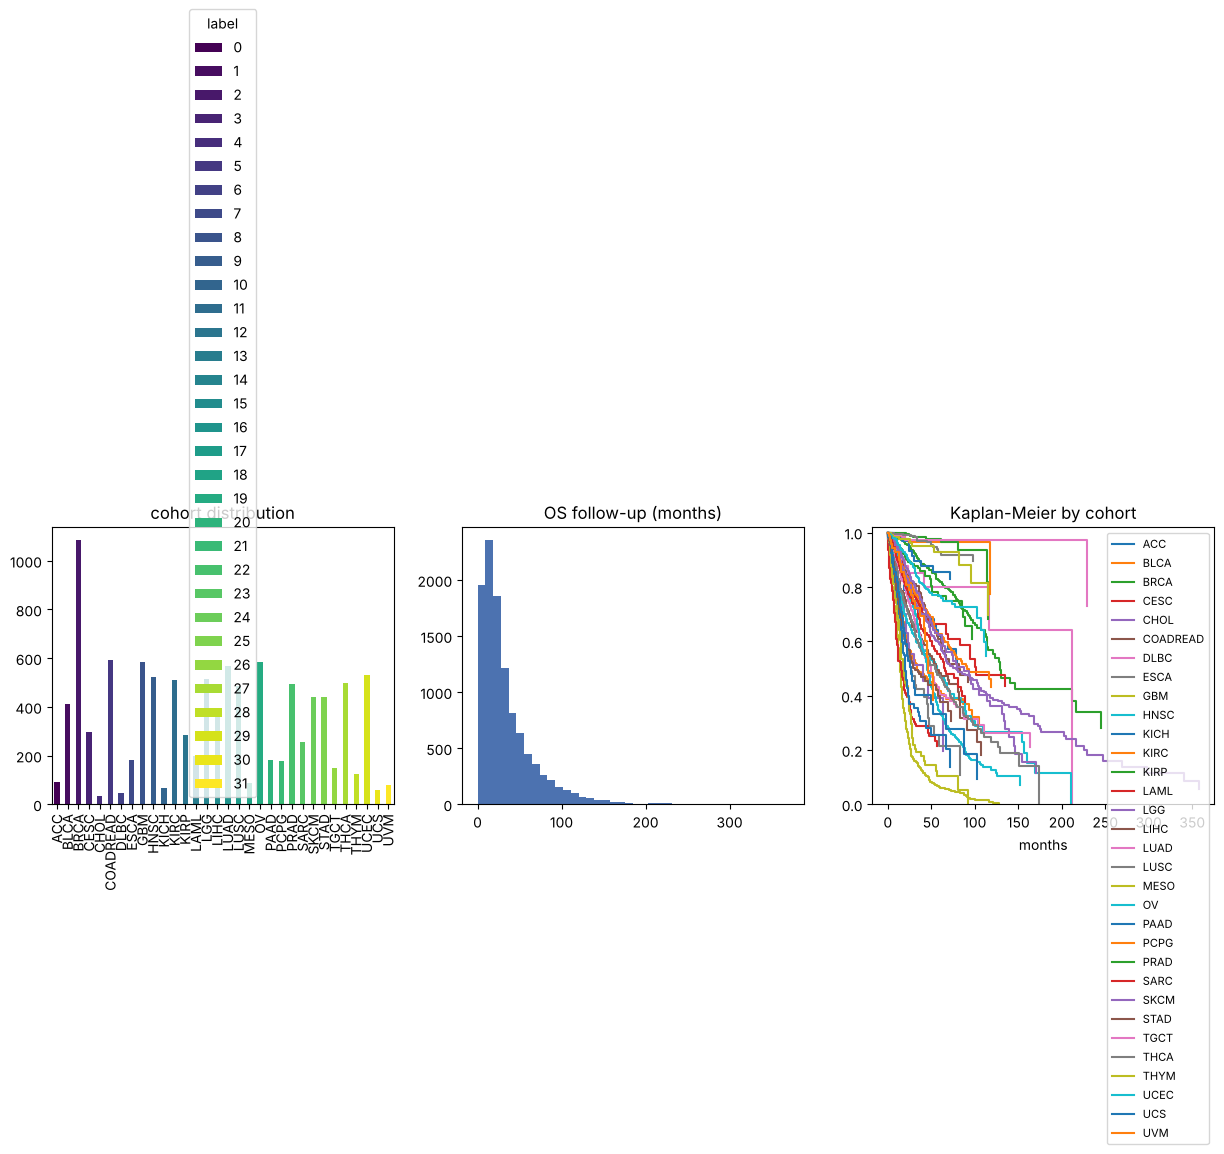

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))

# class balance per cohort
lab = pd.DataFrame({"cohort": [sk.cohort_names[c] for c in sk.cohort_id],
                    "label": sk.label})
lab = lab[lab.label >= 0]
pd.crosstab(lab.cohort, lab.label).plot(kind="bar", stacked=True, ax=ax[0],
                                        colormap="viridis")
ax[0].set_title(f"{cfg.data.class_target} distribution"); ax[0].set_xlabel("")

# follow-up
ax[1].hist(sk.time[np.isfinite(sk.time)], bins=40, color="#4C72B0")
ax[1].set_title(f"{cfg.data.survival_endpoint} follow-up (months)")

# Kaplan-Meier per cohort
from mosaic.metrics import km_curve
for ci, name in enumerate(sk.cohort_names):
    m = sk.cohort_id == ci
    t, s = km_curve(sk.time[m], np.nan_to_num(sk.event[m], nan=0))
    ax[2].step(t, s, where="post", label=name)
ax[2].set_title("Kaplan-Meier by cohort"); ax[2].set_xlabel("months")
ax[2].set_ylim(0, 1.02); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. One fold, end to end

`build_fold` re-fits **everything** that could leak — gene selection, the gene
graph, scalers, survival bin edges — on the training rows only. Held-out
patients are passed through `transform` and attach to training anchors in the
patient graph, never to each other.

In [25]:
from sklearn.model_selection import StratifiedKFold
from mosaic.data.preprocess import stratification_key

strat = stratification_key(sk)
idx = np.arange(len(sk))
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=cfg.train.seed)
train_idx, test_idx = next(iter(skf.split(idx, strat)))

inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=cfg.train.seed)
fit_i, val_i = next(inner.split(train_idx, strat[train_idx]))
fit_idx, val_idx = train_idx[fit_i], train_idx[val_i]
print(f"train={len(fit_idx)}  val={len(val_idx)}  test={len(test_idx)}")

tensors, prep, data = exp.build_fold(train_idx)
n_classes = max(int(sk.label.max()) + 1, 2)
print(tensors.graph.summary())
print("node feature tensor:", tuple(tensors.x.shape),
      "| clinical:", tuple(tensors.clinical.shape))

train=5841  val=2921  test=2191


[graph] GeneGraph(genes=80, edges=1294, per_relation={1: 1214, 2: 80}, modules=64)
GeneGraph(genes=80, edges=1294, per_relation={1: 1214, 2: 80}, modules=64)
node feature tensor: (10953, 80, 6) | clinical: (10953, 84)


In [26]:
%time model = exp.train_fold(tensors, fit_idx, val_idx, n_classes)
result = exp.evaluate_fold(model, tensors, test_idx, train_idx)

show = {k: v for k, v in result.items()
        if isinstance(v, (int, float)) and not k.startswith("_")}
display(pd.Series(show).to_frame("value").round(4))
print("\nper-cohort:")
display(pd.DataFrame(result["per_cohort"]).T.round(3))

  epoch   4 total=1207.393 val_score=0.6783 bacc=0.614 cidx=0.742


CPU times: user 16min 17s, sys: 1min 39s, total: 17min 56s
Wall time: 4min 45s


,value
accuracy,0.6476
balanced_accuracy,0.6153
f1_macro,0.5603
f1_weighted,0.6593
precision_macro,0.5681
recall_macro,0.6153
specificity_macro,0.9886
npv_macro,0.9886
kappa,0.6326
kappa_quadratic,0.6869



per-cohort:


,accuracy,balanced_accuracy,f1_macro,f1_weighted,precision_macro,recall_macro,specificity_macro,npv_macro,kappa,kappa_quadratic,mcc,log_loss,brier,top2_accuracy,c_index,n
ACC,0.895,0.895,0.315,0.944,0.333,0.298,NaN,0.0,0.0,0.0,0.0,1.250,0.548,0.947,0.663,19.0
BLCA,0.610,0.610,0.076,0.758,0.100,0.061,NaN,0.0,0.0,0.0,0.0,1.478,0.605,0.805,0.682,82.0
BRCA,0.793,0.793,0.068,0.884,0.077,0.061,NaN,0.0,0.0,0.0,0.0,1.238,0.485,0.866,0.639,217.0
CESC,0.864,0.864,0.232,0.927,0.250,0.216,NaN,0.0,0.0,0.0,0.0,1.189,0.440,0.898,0.634,59.0
COADREAD,0.655,0.655,0.057,0.792,0.071,0.047,NaN,0.0,0.0,0.0,0.0,1.648,0.655,0.790,0.745,119.0
DLBC,0.700,0.700,0.206,0.824,0.250,0.175,NaN,0.0,0.0,0.0,0.0,1.729,0.724,0.800,0.692,10.0
ESCA,0.694,0.694,0.091,0.820,0.111,0.077,NaN,0.0,0.0,0.0,0.0,1.551,0.617,0.778,0.677,36.0
GBM,0.667,0.667,0.100,0.800,0.125,0.083,NaN,0.0,0.0,0.0,0.0,1.382,0.570,0.812,0.525,117.0
HNSC,0.686,0.686,0.058,0.814,0.071,0.049,NaN,0.0,0.0,0.0,0.0,1.400,0.469,0.743,0.660,105.0
KICH,0.231,0.231,0.054,0.375,0.143,0.033,NaN,0.0,0.0,0.0,0.0,2.218,0.905,0.615,1.000,13.0


### 5.1 Figure — risk stratification

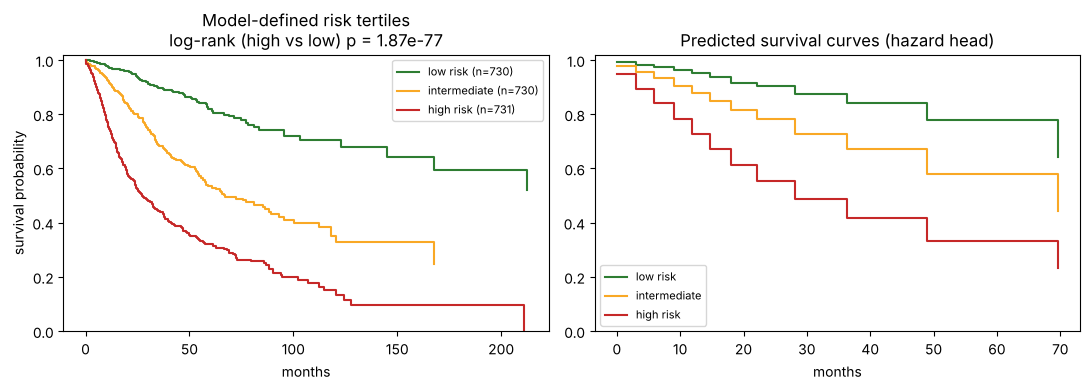

In [27]:
from mosaic.metrics import km_curve, logrank_test

pred = exp.predict(model, tensors, test_idx, anchor_idx=train_idx,
                   mc_samples=cfg.train.mc_dropout_samples)
t_te = tensors.time.numpy()[test_idx]
e_te = tensors.event.numpy()[test_idx]
y_te = tensors.label.numpy()[test_idx]

cuts = np.quantile(pred["risk"], [1/3, 2/3])
group = np.digitize(pred["risk"], cuts)
names = ["low risk", "intermediate", "high risk"]
colors = ["#2E7D32", "#F9A825", "#C62828"]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for g in range(3):
    m = group == g
    if m.sum() < 5:
        continue
    t, s = km_curve(t_te[m], e_te[m])
    ax[0].step(t, s, where="post", color=colors[g],
               label=f"{names[g]} (n={int(m.sum())})")
hi_lo = np.isin(group, [0, 2])
chi2, p = logrank_test(t_te[hi_lo], e_te[hi_lo], (group[hi_lo] == 2).astype(int))
ax[0].set_title(f"Model-defined risk tertiles\nlog-rank (high vs low) p = {p:.2e}")
ax[0].set_xlabel("months"); ax[0].set_ylabel("survival probability")
ax[0].set_ylim(0, 1.02); ax[0].legend(fontsize=8)

# predicted individual survival curves from the discrete-time hazard head
edges = np.concatenate([[0], prep.surv_bins])
for g, c in zip(range(3), colors):
    m = group == g
    if m.any():
        ax[1].step(edges[:pred["survival"].shape[1]],
                   pred["survival"][m].mean(0), where="post", color=c,
                   label=names[g])
ax[1].set_title("Predicted survival curves (hazard head)")
ax[1].set_xlabel("months"); ax[1].set_ylim(0, 1.02); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_km_risk.png", dpi=200); plt.show()

### 5.2 Figure — classification quality and uncertainty

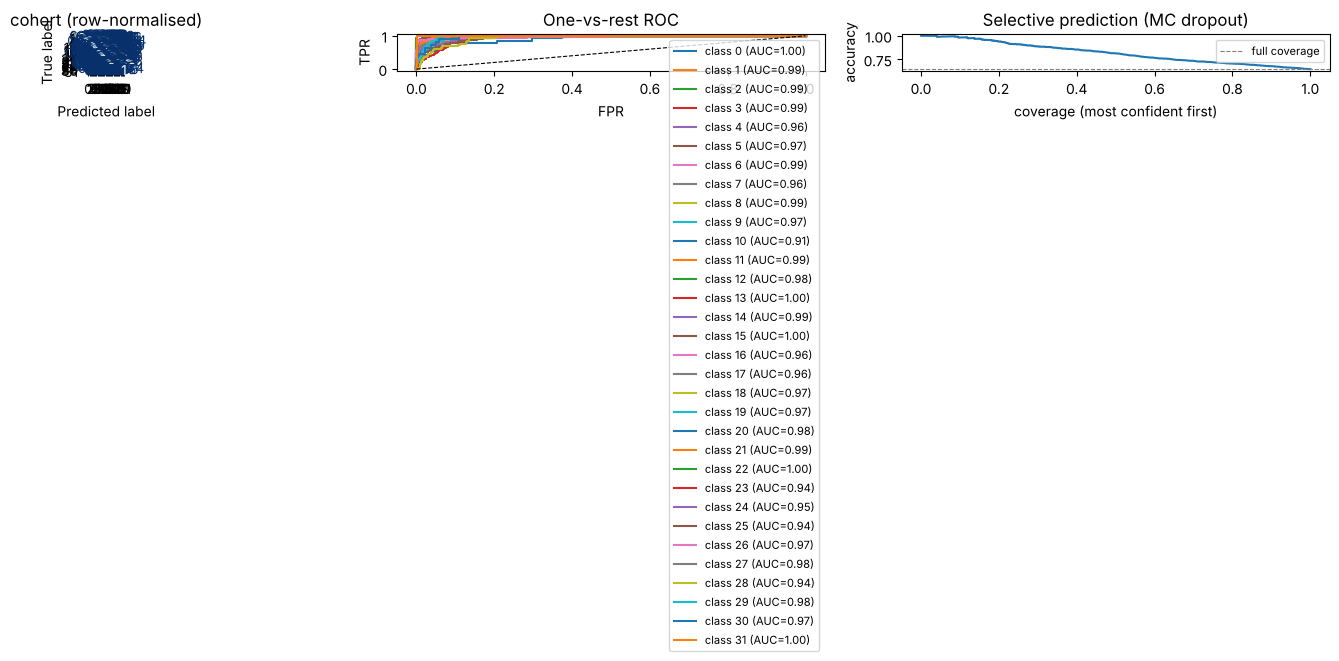

In [28]:
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, auc

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
m = y_te >= 0

ConfusionMatrixDisplay.from_predictions(
    y_te[m], pred["prob"][m].argmax(1), normalize="true", cmap="Blues",
    colorbar=False, ax=ax[0])
ax[0].set_title(f"{cfg.data.class_target} (row-normalised)")

for c in np.unique(y_te[m]):
    fpr, tpr, _ = roc_curve((y_te[m] == c).astype(int), pred["prob"][m][:, c])
    ax[1].plot(fpr, tpr, label=f"class {c} (AUC={auc(fpr, tpr):.2f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR")
ax[1].set_title("One-vs-rest ROC"); ax[1].legend(fontsize=8)

# selective prediction: MC-dropout entropy as an abstention signal
order = np.argsort(pred["entropy"][m])
correct = (pred["prob"][m].argmax(1) == y_te[m])[order]
cov = np.arange(1, len(order) + 1) / len(order)
ax[2].plot(cov, np.cumsum(correct) / np.arange(1, len(order) + 1))
ax[2].axhline(correct.mean(), ls="--", c="grey", lw=0.8, label="full coverage")
ax[2].set_xlabel("coverage (most confident first)"); ax[2].set_ylabel("accuracy")
ax[2].set_title("Selective prediction (MC dropout)"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_classification.png", dpi=200)
plt.show()

## 6. Full experiments

These are the four tables the manuscript needs. They are slow — set
`RUN_FULL = True` in the configuration cell (GPU strongly recommended).

In [29]:
cv = None
if RUN_FULL and NB_FOLDS >= 2:
    print(f"cross-validation: {NB_REPEATS} repeat(s) x {NB_FOLDS} folds, "
          f"{EPOCHS} epochs, {MAX_GENES} genes "
          f"({NB_REPEATS * NB_FOLDS} fits). The manuscript uses 5 folds via "
          f"scripts/run_pan.sh; fold counts are reported with every number.")
    cv = exp.run_cv()
    summary = pd.DataFrame(cv["summary"]).T[["mean", "std", "n"]]
    display(summary.round(4))
elif RUN_FULL:
    # Every other phase below guards its own budget and says why it was
    # skipped. This one did not, so MOSAIC_NB_FOLDS=1 -- an obvious choice
    # for a quick pass -- reached StratifiedKFold(n_splits=1) and raised
    # instead of skipping, leaving a traceback in the middle of an otherwise
    # clean notebook. One fold is not a cross-validation; say so and move on.
    print(f"cross-validation: NOT RUN (MOSAIC_NB_FOLDS={NB_FOLDS}). "
          "Cross-validation needs at least 2 folds -- with one fold there is "
          "no second split to average over, and scikit-learn rejects "
          "n_splits=1. Set MOSAIC_NB_FOLDS=2 or more. The held-out fold "
          "evaluated above is unaffected; it is a single split, reported as "
          "one.")
else:
    print("RUN_FULL is False - skipping repeated cross-validation.")

cross-validation: 1 repeat(s) x 2 folds, 4 epochs, 80 genes (2 fits). The manuscript uses 5 folds via scripts/run_pan.sh; fold counts are reported with every number.

=== repeat 1/1 fold 1/2 (train=2738 val=2738 test=5477)


[graph] GeneGraph(genes=80, edges=1280, per_relation={1: 1200, 2: 80}, modules=64)


  epoch   4 total=625.774 val_score=0.6414 bacc=0.544 cidx=0.739


[fold] bacc=0.542 auroc=0.957 c_index=0.731 logrank_p=3.19e-144 (1690.4s)
[checkpoint] wrote 1/2 folds to ./runs_notebook/cohort_results.json

=== repeat 1/1 fold 2/2 (train=2738 val=2739 test=5476)


[graph] GeneGraph(genes=80, edges=1326, per_relation={1: 1246, 2: 80}, modules=64)


  epoch   4 total=624.159 val_score=0.6271 bacc=0.511 cidx=0.743


[fold] bacc=0.534 auroc=0.955 c_index=0.737 logrank_p=4.57e-137 (1605.9s)
[checkpoint] wrote 2/2 folds to ./runs_notebook/cohort_results.json


,mean,std,n
accuracy,0.6030,0.0021,2.0
balanced_accuracy,0.5380,0.0062,2.0
f1_macro,0.5027,0.0061,2.0
f1_weighted,0.6083,0.0038,2.0
precision_macro,0.5238,0.0052,2.0
recall_macro,0.5380,0.0062,2.0
specificity_macro,0.9872,0.0001,2.0
npv_macro,0.9871,0.0000,2.0
kappa,0.5853,0.0022,2.0
kappa_quadratic,0.6564,0.0136,2.0


In [30]:
baseline_table = None
if RUN_FULL:
    from mosaic.baselines import run_baseline_suite
    per_fold, per_fold_preds, per_fold_split = [], [], []
    print(f"baseline panel: {NB_BASELINE_FOLDS} of {NB_FOLDS} folds. "
          f"Twenty-four models over {len(idx)} patients is the slowest phase "
          f"here; the fold count is reported with every baseline number.")
    for f, (tr, te) in enumerate(skf.split(idx, strat)):
        if f >= NB_BASELINE_FOLDS:
            break
        tn, _, dt = exp.build_fold(tr)
        print(f"baseline fold {f + 1}/{NB_BASELINE_FOLDS}")
        m, pr = run_baseline_suite(
            tn.x.numpy(), tn.clinical.numpy(), dt.label, dt.time, dt.event,
            tr, te, n_classes, block_names=sorted(sk.blocks),
            seed=cfg.train.seed, device=str(exp.device))
        per_fold.append(m)
        per_fold_preds.append(pr)
        per_fold_split.append((tr, te))
    # Keep every metric each baseline reported, not just three: the comparison
    # table in the paper is the full panel, and averaging is done per metric so
    # a model that could not produce one (e.g. a survival-only model has no
    # accuracy) leaves a blank rather than a zero.
    all_metrics = sorted({m for f in per_fold for d in f.values() for m in d})
    baseline_table = pd.DataFrame({
        name: {metric: np.nanmean([f[name].get(metric, np.nan) for f in per_fold])
               for metric in all_metrics}
        for name in sorted(per_fold[0])}).T
    if cv is not None:
        baseline_table.loc["MOSAIC-GNN"] = {
            m: cv["summary"].get(m, {}).get("mean", np.nan) for m in all_metrics}
    baseline_table.to_csv(f"{OUT_DIR}/table3_comparison_full.csv")
    display(baseline_table[[c for c in ("balanced_accuracy", "auroc", "c_index")
                            if c in baseline_table]].round(3))
else:
    print("RUN_FULL is False - skipping baselines.")

baseline panel: 1 of 2 folds. Twenty-four models over 10953 patients is the slowest phase here; the fold count is reported with every baseline number.


[graph] GeneGraph(genes=80, edges=1294, per_relation={1: 1214, 2: 80}, modules=64)
baseline fold 1/1


  logistic_l2              bacc=0.933 auroc=0.998 c-index=nan


  logistic_l1              fit took 192s


  logistic_l1              bacc=0.930 auroc=0.998 c-index=nan


  logistic_elasticnet      fit took 198s


... (21 outputs left out)

  cox_clinical_only        bacc=nan auroc=nan c-index=0.734


  random_survival_forest   not run (MOSAIC_SKIP_BASELINES)


  deepsurv                 bacc=nan auroc=nan c-index=0.757


,balanced_accuracy,auroc,c_index
cox_clinical_only,NaN,NaN,0.734
cox_lasso,NaN,NaN,0.766
cox_ridge,NaN,NaN,0.764
deepsurv,NaN,NaN,0.757
extra_trees,0.869,0.996,NaN
hist_gradient_boosting,0.928,0.999,NaN
knn,0.688,0.969,NaN
late_fusion_mlp,0.923,0.999,0.771
lda_shrinkage,0.897,0.992,NaN
lightgbm,0.934,0.999,NaN


ablation: 2 of 8 variants (full, no_gene_graph), 1 repeat x 2 folds each. The manuscript's ablation table comes from scripts/run_pan.sh.
ablation: full


[data] patients=10953 cohorts=['ACC', 'BLCA', 'BRCA', 'CESC', 'CHOL', 'COADREAD', 'DLBC', 'ESCA', 'GBM', 'HNSC', 'KICH', 'KIRC', 'KIRP', 'LAML', 'LGG', 'LIHC', 'LUAD', 'LUSC', 'MESO', 'OV', 'PAAD', 'PCPG', 'PRAD', 'SARC', 'SKCM', 'STAD', 'TGCT', 'THCA', 'THYM', 'UCEC', 'UCS', 'UVM'] classes=32 blocks=['cna', 'exp', 'mut']
[data] survival events=3543 median_followup=23.4 months

=== repeat 1/1 fold 1/2 (train=2738 val=2738 test=5477)


[graph] GeneGraph(genes=80, edges=1280, per_relation={1: 1200, 2: 80}, modules=64)


  epoch   4 total=625.780 val_score=0.6409 bacc=0.543 cidx=0.739


[fold] bacc=0.542 auroc=0.957 c_index=0.731 logrank_p=3.87e-144 (1506.1s)
[checkpoint] wrote 1/2 folds to ./runs_notebook/cohort-full_results.json

=== repeat 1/1 fold 2/2 (train=2738 val=2739 test=5476)


[graph] GeneGraph(genes=80, edges=1326, per_relation={1: 1246, 2: 80}, modules=64)


... (6 outputs left out)

[graph] GeneGraph(genes=80, edges=1326, per_relation={1: 1246, 2: 80}, modules=64)


  epoch   4 total=625.096 val_score=0.6428 bacc=0.537 cidx=0.749


[fold] bacc=0.558 auroc=0.958 c_index=0.741 logrank_p=3.55e-150 (1356.1s)
[checkpoint] wrote 2/2 folds to ./runs_notebook/cohort-no_gene_graph_results.json


,balanced_accuracy,auroc,c_index
full,0.538,0.956,0.734
no_gene_graph,0.535,0.956,0.737


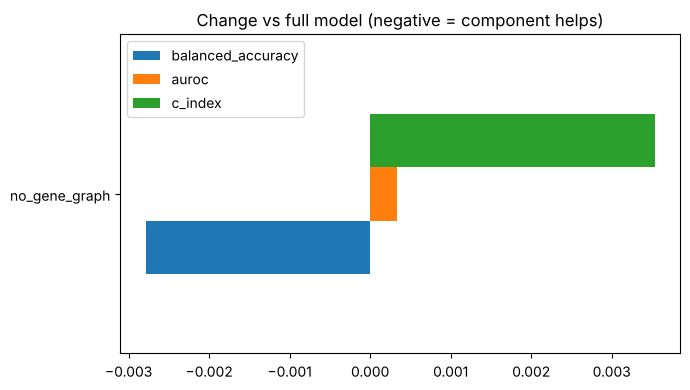

In [31]:
ablation_table = None
if RUN_FULL and NB_ABLATIONS > 0:
    from mosaic.cli import ABLATIONS
    from mosaic.config import Config as C
    rows = {}
    # Each ablation is a whole cross-validation, so the full set is
    # len(ABLATIONS) x NB_FOLDS fits. "full" is always included, because every
    # other row is only meaningful as a difference from it.
    chosen = ["full"] + [k for k in ABLATIONS if k != "full"][:NB_ABLATIONS]
    print(f"ablation: {len(chosen)} of {len(ABLATIONS)} variants "
          f"({', '.join(chosen)}), 1 repeat x {NB_FOLDS} folds each. "
          f"The manuscript's ablation table comes from scripts/run_pan.sh.")
    for name, override in [(k, ABLATIONS[k]) for k in chosen
                           if k in ABLATIONS]:
        mcfg = type(cfg.model)(**{**cfg.model.__dict__, **override})
        tcfg = type(cfg.train)(**{**cfg.train.__dict__, "n_repeats": 1})
        sub = C(data=cfg.data, graph=cfg.graph, model=mcfg, loss=cfg.loss,
                train=tcfg, tag=f"{cfg.tag}-{name}")
        print("ablation:", name)
        e = Experiment(sub); e.prepare()
        s = e.run_cv()["summary"]
        rows[name] = {k: s.get(k, {}).get("mean", np.nan)
                      for k in ("balanced_accuracy", "auroc", "c_index")}
    ablation_table = pd.DataFrame(rows).T
    display(ablation_table.round(3))
    (ablation_table - ablation_table.loc["full"]).drop("full").plot(
        kind="barh", figsize=(7, 4), title="Change vs full model (negative = component helps)")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_ablation.png", dpi=200); plt.show()
else:
    print("ablation: NOT RUN (MOSAIC_NB_ABLATIONS=0). Each variant is a full "
          "cross-validation, so the complete set is 8 x NB_FOLDS fits. The "
          "manuscript's ablation table comes from scripts/run_pan.sh.")

In [32]:
loco_table = None
if RUN_FULL and NB_LOCO > 0:
    rows = {}
    held_out = list(cfg.data.cohorts)[:NB_LOCO]
    print(f"leave-one-cancer-out: {len(held_out)} of "
          f"{len(cfg.data.cohorts)} cohorts ({', '.join(held_out)}), one fit "
          f"each. On the {TARGET} target note that a held-out class is never "
          f"seen in training, so its balanced accuracy is near zero by "
          f"construction -- only the survival transfer carries information.")
    for held in held_out:
        a, b = exp.offsets[held]
        te = np.arange(a, b)
        tr = np.setdiff1d(idx, te)
        rng = np.random.default_rng(cfg.train.seed)
        va = rng.choice(tr, size=max(int(0.15 * len(tr)), 20), replace=False)
        ft = np.setdiff1d(tr, va)
        print("leave out:", held)
        tn, _, _ = exp.build_fold(tr)
        mdl = exp.train_fold(tn, ft, va, n_classes)
        r = exp.evaluate_fold(mdl, tn, te, tr)
        rows[held] = {k: r.get(k, np.nan) for k in
                      ("balanced_accuracy", "auroc", "c_index", "logrank_p")}
    loco_table = pd.DataFrame(rows).T
    display(loco_table.round(3))
else:
    print("leave-one-cancer-out: NOT RUN (MOSAIC_NB_LOCO=0). One fit per "
          "cohort means 32 fits on the pan-cancer data. The manuscript's "
          "transfer table comes from scripts/run_pan.sh.")

leave-one-cancer-out: 1 of 32 cohorts (ACC), one fit each. On the cohort target note that a held-out class is never seen in training, so its balanced accuracy is near zero by construction -- only the survival transfer carries information.
leave out: ACC


[graph] GeneGraph(genes=80, edges=1280, per_relation={1: 1200, 2: 80}, modules=64)


  epoch   4 total=2271.735 val_score=0.4409 bacc=0.119 cidx=0.763


,balanced_accuracy,auroc,c_index,logrank_p
ACC,1.0,NaN,0.772,0.0


## 7. Interpretation

Three complementary attributions, because attention on its own is not evidence:
module attention (which pathways drive the embedding), the within-module gene
gate (which genes dominate), and integrated gradients on the node features
(signed, per-omic, baseline-referenced).

In [33]:
from mosaic.explain import (collect_attention, export_ranked_gene_list,
                            gene_importance_table, integrated_gradients,
                            module_importance_table, personalised_subnetwork)

att = collect_attention(model, tensors, test_idx, exp.device)
ig = integrated_gradients(model, tensors, test_idx[:min(len(test_idx), 128)],
                          exp.device, target="risk")
blocks = sorted(sk.blocks)

genes_df = gene_importance_table(tensors.graph.genes, tensors.graph.modules,
                                 tensors.graph.module_names, att["gene_gate"],
                                 ig, blocks)
modules_df = module_importance_table(tensors.graph.module_names,
                                     att["module_attention"],
                                     tensors.graph.modules, tensors.graph.genes,
                                     gate=att["gene_gate"])
genes_df.to_csv(f"{OUT_DIR}/gene_importance.csv", index=False)
modules_df.to_csv(f"{OUT_DIR}/module_importance.csv", index=False)
export_ranked_gene_list(genes_df, f"{OUT_DIR}/genes.rnk")   # feed to GSEA / g:Profiler

display(genes_df.head(25))
display(modules_df.head(10))

,gene,module,gate_mean,gate_std,ig_abs,ig_cna,ig_exp,ig_mut
0,AURKB,MODULE_011,0.457636,0.091342,0.012992,0.000445,-0.007143,0.000000e+00
1,FANCA,MODULE_019,1.000000,0.000000,0.008864,0.000036,-0.005058,-3.012415e-05
2,CARD11,MODULE_056,1.000000,0.000000,0.007635,0.000200,-0.005925,-3.044169e-06
3,RECQL4,MODULE_002,1.000000,0.000000,0.006847,-0.000455,-0.003340,-2.209157e-05
4,CHEK2,MODULE_016,1.000000,0.000000,0.005649,0.000476,-0.002666,-1.611416e-05
5,RAC1,MODULE_021,0.503124,0.105969,0.005613,-0.000223,-0.002762,-4.977056e-06
6,H3-3B,MODULE_011,0.542364,0.091342,0.005523,0.000096,-0.003838,2.155383e-07
7,CDKN2A,MODULE_012,0.513237,0.087777,0.005378,0.000244,-0.003583,-4.236248e-05
8,KMT2B,MODULE_038,1.000000,0.000000,0.004972,-0.000135,-0.003227,-4.717838e-05
9,PBRM1,MODULE_042,1.000000,0.000000,0.004691,0.000102,-0.000122,2.627544e-06


,module,size,attention,top_genes
0,MODULE_011,2,0.043408,"H3-3B, AURKB"
1,MODULE_020,1,0.030581,DUSP4
2,MODULE_022,1,0.029531,ROS1
3,MODULE_031,1,0.029385,TP53
4,MODULE_007,2,0.028767,"CD274, PDCD1LG2"
5,MODULE_012,2,0.026564,"CDKN2A, CDKN2B"
6,MODULE_056,1,0.024638,CARD11
7,MODULE_000,2,0.020913,"ALOX12B, MAP2K4"
8,MODULE_061,1,0.019776,NPM1
9,MODULE_016,1,0.019279,CHEK2


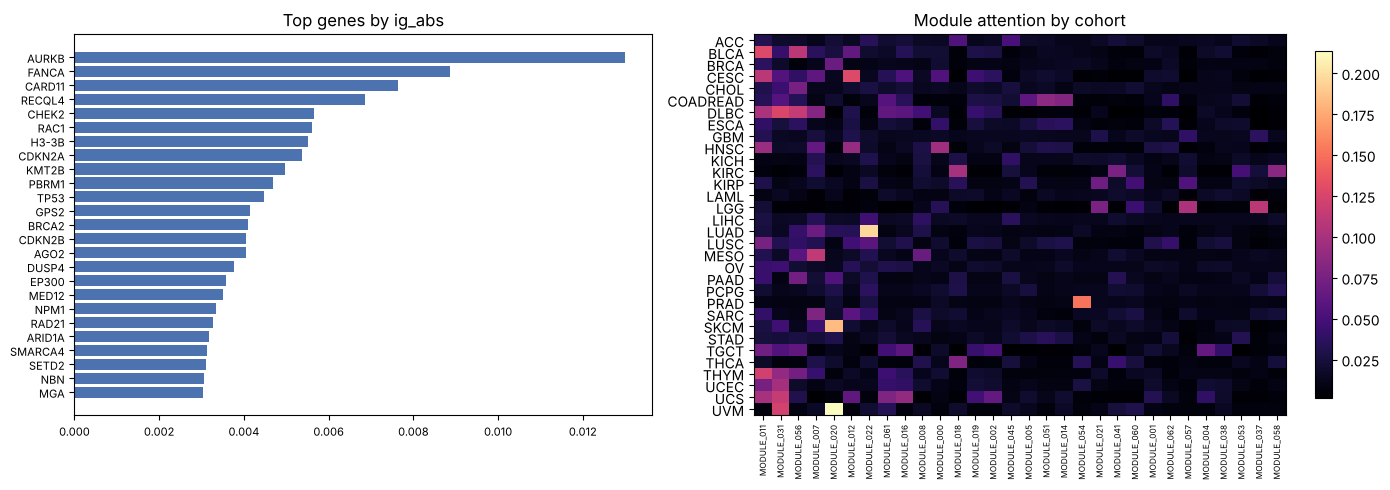

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

top = genes_df.head(25).iloc[::-1]
score_col = "ig_abs" if "ig_abs" in top else "gate_mean"
ax[0].barh(top["gene"], top[score_col], color="#4C72B0")
ax[0].set_title(f"Top genes by {score_col}"); ax[0].tick_params(labelsize=8)

# module attention per cohort -> which pathways matter for which cancer
coh_te = tensors.cohort.numpy()[test_idx]
mat = np.vstack([att["module_attention"][coh_te == c].mean(0)
                 for c in range(len(sk.cohort_names))
                 if (coh_te == c).sum() > 0])
keep = np.argsort(-mat.mean(0))[:30]
im = ax[1].imshow(mat[:, keep], aspect="auto", cmap="magma")
ax[1].set_yticks(range(mat.shape[0]))
ax[1].set_yticklabels([n for c, n in enumerate(sk.cohort_names)
                       if (coh_te == c).sum() > 0])
ax[1].set_xticks(range(len(keep)))
ax[1].set_xticklabels([tensors.graph.module_names[i] for i in keep],
                      rotation=90, fontsize=6)
ax[1].set_title("Module attention by cohort")
plt.colorbar(im, ax=ax[1], fraction=0.03)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_interpretation.png", dpi=200)
plt.show()

In [35]:
# One patient's rewired interaction network -- edges are that patient's own
# attention weights over the shared topology.
sub = personalised_subnetwork(model, tensors, int(test_idx[0]), exp.device,
                              top_edges=150)
sub.to_csv(f"{OUT_DIR}/subnetwork_patient0.csv", index=False)
display(sub.head(15))
print("export this to Cytoscape / networkx for the figure")

,source,target,attention,relation
0,ROS1,ROS1,1.000000,2
1,H3-3B,H3-3B,0.788554,2
2,DUSP4,DUSP4,0.777064,2
3,CARD11,CARD11,0.609423,2
4,GNAS,GNAS,0.586376,2
5,NKX3-1,NKX3-1,0.566640,2
6,ALOX12B,ALOX12B,0.551609,2
7,PMS2,PMS2,0.483556,2
8,NOTCH3,NOTCH3,0.476246,2
9,CDKN2B,CDKN2B,0.457665,2


export this to Cytoscape / networkx for the figure


## 7.5 Overfitting, leakage and sample-size diagnostics

Four checks, because "the test score is high" is not evidence that a model
generalises:

* **Generalisation gap** — train vs validation vs test on the same fold. A gap
  that widens monotonically is memorisation.
* **Learning curves** — the training trace, to see *when* the gap opened.
* **Label permutation test** — retrain on shuffled labels. This is the only
  check that can show the absence of leakage: with the labels destroyed, a
  clean pipeline must fall to chance. If it does not, information about the
  label is reaching the model through a feature.
* **Sample-size curve** — performance against the number of training patients,
  which says whether the result is data-limited or model-limited.

In [ ]:
from mosaic.diagnostics import (generalisation_gap, learning_curves,
                                parameter_report, permutation_p_value,
                                permutation_test, sample_size_curve)

gap = generalisation_gap(exp, tensors, model,
                         {"train": fit_idx, "validation": val_idx,
                          "test": test_idx}, train_idx)
gap_df = pd.DataFrame(gap).T
gap_df.to_csv(f"{OUT_DIR}/tableS1_generalisation_gap.csv")
display(gap_df.round(4))

params = parameter_report(model, n_train=len(fit_idx))
print("parameters:", {k: round(v, 2) if isinstance(v, float) else v
                      for k, v in params.items()})

lc = learning_curves(model)
if lc is not None and len(lc):
    lc.to_csv(f"{OUT_DIR}/tableS1b_learning_curve.csv")
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for col in [c for c in lc.columns if "loss" in c]:
        ax[0].plot(lc.index, lc[col], label=col)
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].legend()
    ax[0].set_title("Training trace")
    for col in [c for c in lc.columns if "loss" not in c]:
        ax[1].plot(lc.index, lc[col], label=col)
    ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].set_title("Validation score")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_learning_curve.png", dpi=200)
    plt.show()

In [ ]:
# Label permutation: expensive, so it is guarded. Run it at least once for the
# write-up -- it is the single most convincing panel in the supplement.
perm_table = None
if RUN_FULL and NB_PERMUTATIONS > 0:
    # With B permutations the smallest attainable p-value is 1/(B+1), so a
    # small B bounds the p-value rather than measuring it. That limit is
    # printed with the result instead of being left for a reader to work out.
    print(f"permutation null: {NB_PERMUTATIONS} permutation(s); the smallest "
          f"attainable p is {1 / (NB_PERMUTATIONS + 1):.3f}. Each permutation "
          f"is a full retrain on shuffled labels.")
    perm_df = permutation_test(exp, tensors, fit_idx, val_idx, test_idx,
                               n_classes, n_permutations=NB_PERMUTATIONS,
                               seed=cfg.train.seed)
    display(perm_df.round(4))

    # Compare the real fold against the shuffled-label null.
    observed = {k: v for k, v in result.items()
                if isinstance(v, (int, float)) and not k.startswith("_")}
    rows = {}
    for metric in ("balanced_accuracy", "auroc", "c_index"):
        if metric not in perm_df.columns or metric not in observed:
            continue
        null = perm_df[metric].dropna().to_numpy(dtype=float)
        if null.size == 0:
            continue
        rows[metric] = {
            "observed": observed[metric],
            "null_mean": float(null.mean()),
            "null_sd": float(null.std(ddof=1)) if null.size > 1 else 0.0,
            "null_max": float(null.max()),
            "n_permutations": int(null.size),
            "p_value": permutation_p_value(observed[metric], null),
        }
    perm_table = pd.DataFrame(rows).T
    perm_table.to_csv(f"{OUT_DIR}/tableS2_permutation_test.csv")
    display(perm_table.round(4))
else:
    print("permutation null: NOT RUN (MOSAIC_NB_PERMUTATIONS=0). Each "
          "permutation is a full retrain. The manuscript's leakage control "
          "comes from scripts/run_pan.sh.")

In [ ]:
ss_df = None
if RUN_FULL and NB_SAMPLE_SIZE > 0:
    print("sample-size curve: one retrain per fraction.")
    ss_df = sample_size_curve(exp, tensors, fit_idx, val_idx, test_idx,
                              n_classes, fractions=(0.25, 0.5, 0.75, 1.0),
                              seed=cfg.train.seed)
    ss_df.to_csv(f"{OUT_DIR}/tableS3_sample_size.csv")
    display(ss_df.round(4))
    # sample_size_curve indexes by n_train, so bring it back as a column.
    plot_df = ss_df.reset_index()
    cols = [c for c in plot_df.columns if c not in ("n_train", "fraction")]
    plot_df.plot(x="n_train", y=cols, marker="o", figsize=(7, 4),
                 title="Performance vs training-set size")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_sample_size.png", dpi=200)
    plt.show()
else:
    print("sample-size curve: NOT RUN (MOSAIC_NB_SAMPLE_SIZE=0). It retrains "
          "once per fraction of the training set; at pan-cancer scale that is "
          "four more full fits for a supplementary panel.")

## 7.6 Export every table

Writes the CSVs that `scripts/build_manuscript.py` turns into the Word tables,
under the exact names it expects. Anything that was skipped is simply absent,
and the manuscript builder omits that table rather than inventing numbers.

In [ ]:
import os
os.makedirs(OUT_DIR, exist_ok=True)

# --- Table 1: cohort characteristics ---------------------------------------
cohort_table.set_index("cohort").to_csv(f"{OUT_DIR}/table1_cohorts.csv")

# --- Table 2: the full metric panel on the held-out fold -------------------
panel = {k: v for k, v in result.items()
         if isinstance(v, (int, float)) and not k.startswith("_")}
pd.Series(panel).to_frame("value").to_csv(f"{OUT_DIR}/table2_single_fold.csv")

# --- Table 2b / 2c: per class and per cohort ------------------------------
if "per_class" in result:
    pd.DataFrame(result["per_class"]).T.to_csv(f"{OUT_DIR}/table2b_per_class.csv")
if "per_cohort" in result:
    pd.DataFrame(result["per_cohort"]).T.to_csv(f"{OUT_DIR}/table2c_per_cohort.csv")

# --- Table 4: paired tests, MOSAIC-GNN against every baseline -------------
# A difference in means is not a result; the paired bootstrap on the same test
# patients is, and the p-values are corrected for the number of comparisons.
if RUN_FULL and baseline_table is not None:
    from sklearn.metrics import balanced_accuracy_score

    from mosaic.metrics import (benjamini_hochberg, concordance_index,
                                paired_bootstrap_test)

    # Fold 0 of the same StratifiedKFold is the primary fold, so `model`,
    # `test_idx` and the fold-0 baseline predictions all describe the same
    # patients -- which is what makes the test paired.
    tr0, te0 = per_fold_split[0]
    assert np.array_equal(te0, test_idx), "fold 0 must match the primary fold"
    ours_pred = exp.predict(model, tensors, test_idx, anchor_idx=train_idx)

    y_te = sk.label[test_idx]
    t_te = sk.time[test_idx]
    e_te = np.nan_to_num(sk.event[test_idx], nan=0.0)

    lab_ok = y_te >= 0
    surv_ok = np.isfinite(t_te) & (t_te > 0)

    def bacc(y, p):
        return balanced_accuracy_score(y, p.argmax(1))

    def cidx(packed, risk):
        return concordance_index(packed[:, 0], risk, packed[:, 1])

    rows = []
    for name, pr in per_fold_preds[0].items():
        row = {"model": name}
        if pr.get("prob") is not None and lab_ok.sum() > 1:
            r = paired_bootstrap_test(bacc, y_te[lab_ok],
                                      ours_pred["prob"][lab_ok],
                                      np.asarray(pr["prob"])[lab_ok],
                                      seed=cfg.train.seed)
            row.update({"bacc_delta": r["delta"], "bacc_p": r["p_value"],
                        "bacc_ci_low": r.get("ci_low"),
                        "bacc_ci_high": r.get("ci_high")})
        if pr.get("risk") is not None and surv_ok.sum() > 1:
            packed = np.column_stack([t_te[surv_ok], e_te[surv_ok]])
            r = paired_bootstrap_test(cidx, packed,
                                      ours_pred["risk"][surv_ok],
                                      np.asarray(pr["risk"])[surv_ok],
                                      seed=cfg.train.seed)
            row.update({"cindex_delta": r["delta"], "cindex_p": r["p_value"],
                        "cindex_ci_low": r.get("ci_low"),
                        "cindex_ci_high": r.get("ci_high")})
        rows.append(row)

    paired = pd.DataFrame(rows).set_index("model")
    # One correction over every test in the table, not per column.
    for col in [c for c in paired.columns if c.endswith("_p")]:
        q, rej = benjamini_hochberg(paired[col].tolist())
        paired[col.replace("_p", "_q")] = q
        paired[col.replace("_p", "_sig")] = rej
    paired.to_csv(f"{OUT_DIR}/table4_paired_tests.csv")
    display(paired.round(4))

# --- Tables 5 / 6: ablation and leave-one-cancer-out ----------------------
if ablation_table is not None:
    ablation_table.to_csv(f"{OUT_DIR}/table5_ablation.csv")
if loco_table is not None:
    loco_table.to_csv(f"{OUT_DIR}/table6_loco.csv")

# --- Tables 7 / 8 / 9: interpretation ------------------------------------
genes_df.head(40).set_index(genes_df.columns[0]).to_csv(
    f"{OUT_DIR}/table7_gene_importance.csv")
modules_df.head(20).set_index(modules_df.columns[0]).to_csv(
    f"{OUT_DIR}/table8_module_importance.csv")
sub.head(25).to_csv(f"{OUT_DIR}/table9_patient_subnetwork.csv")

print("tables written to", OUT_DIR)
for f in sorted(os.listdir(OUT_DIR)):
    if f.endswith(".csv"):
        print("  ", f)

## 8. Before you write it up

- Report **mean ± sd over ≥ 3 repeats × 5 folds**, never a single split.
- Tune baselines on the *same* inner splits as the model.
- Give a **paired bootstrap p-value** for every headline comparison
  (`mosaic.metrics.paired_bootstrap_test`).
- Show **per-cohort** numbers next to the pooled pan-cancer number.
- Report the **leave-one-cancer-out** result even where it is weak — it is the
  honest measure of "pan-cancer".
- Cross-check the top-ranked genes against COSMIC CGC / OncoKB, and present the
  novel ones as **hypotheses**, not findings.
- State the limitations explicitly: cohort sizes in the hundreds → wide survival
  CIs; the co-alteration fallback graph is not a validated interaction network;
  attention-derived rankings need orthogonal validation.